# 9장. 회귀 분석으로 숫자 예측하기

이 Notebook의 핵심은 높은 점수를 만드는 것이 아니라 다음 순서를 지키는 것입니다.

`예측 시점 → 누수 방지 → 시간 분할 → Train TimeSeriesSplit → 모델 선택 고정 → Final Test → Baseline 비교`

**Final Test 결과를 보고 모델을 고르지 않습니다.**

## 제출 정보
- 이름: 유은송
- GitHub ID: song-03
- 작성일: 2026.11.08.
- 최종 Notebook URL: https://github.com/song-03/llm-data-analysis-study/blob/main/chapter09/chapter09.ipynb

## 0. 실행 전 확인

Chapter09는 Chapter05의 오류 탐지용 전용 Raw가 아니라 **공통 프로젝트 `data/raw`**를 사용합니다. 먼저 프로젝트 루트에서 다음 명령을 실행해 관계 검증을 통과한 모델링 입력을 준비합니다.

```powershell
python scripts/prepare_ch09_data.py
```

이 명령은 공통 `data/raw`를 전처리하고 FK 관계를 검증한 뒤 `data/processed/*_clean.csv`를 생성합니다.

In [1]:
from pathlib import Path
import sys
import pandas as pd

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in (CURRENT_DIR, *CURRENT_DIR.parents) if (p / 'src' / 'regression.py').exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'

from src.regression import (
    FEATURE_COLUMNS,
    FORBIDDEN_FEATURES,
    TARGET_COLUMN,
    build_feature_audit,
    build_leakage_checklist,
    build_regression_dataset,
    build_regression_validation,
    build_split_summary,
    create_prediction_result,
    cross_validate_regression_models,
    load_regression_source_data,
    make_regression_models,
    run_regression_analysis,
    save_regression_outputs,
    select_diagnostic_model,
    split_model_data_by_time,
    train_and_evaluate_models,
    validate_feature_columns,
)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('PROCESSED_DIR:', PROCESSED_DIR)

PROJECT_ROOT: C:\dev\llm-data-analysis-course
PROCESSED_DIR: C:\dev\llm-data-analysis-course\data\processed


## 1. 예측 문제와 예측 시점

- Target: 주문 1건의 주문 상세 금액 합계 `order_total`
- 예측 시점: 주문 메타데이터와 고객의 비식별 특성은 알 수 있지만 주문 상세 수량·단가·금액은 모델에 제공하지 않는 시점
- 목표 계산 재료와 사후 정보, 식별자는 feature에서 제외합니다.

In [2]:
print('Target:', TARGET_COLUMN)
print('Allowed features:', FEATURE_COLUMNS)
print('Forbidden features:', sorted(FORBIDDEN_FEATURES))
validate_feature_columns()
print('Feature leakage gate: PASS')

Target: order_total
Allowed features: ['order_month', 'order_dayofweek', 'age', 'payment_method', 'gender', 'city']
Forbidden features: ['avg_unit_price', 'customer_id', 'item_count', 'line_total', 'order_id', 'order_status', 'order_total', 'product_id', 'quantity', 'total_quantity', 'unit_price']
Feature leakage gate: PASS


### 1. 예측 문제 정의

#### 결과 관찰

- Target: 주문 1건의 상세 금액 합계인 `order_total`
- 예측 단위: `order_id`로 구분되는 주문 1건
- 예측 시점: 주문 월·요일과 결제 방법, 고객의 비식별 특성은 확인되지만 주문 상세의 수량·단가·금액은 아직 모델 입력으로 제공하지 않는 시점
- 예측 시점에 알 수 있는 정보: `order_month`, `order_dayofweek`, `age`, `payment_method`, `gender`, `city`
- 예측 시점에 알 수 없거나 사용하지 않는 정보: `order_total`, `line_total`, `quantity`, `unit_price`, `item_count`, `total_quantity`, `avg_unit_price`, `order_status`와 `order_id`·`customer_id`·`product_id` 같은 식별자

실행 결과 Target은 `order_total`, 최종 허용 feature는 6개로 확인됐고 `validate_feature_columns()`의 Feature leakage gate도 PASS했다. Target은 `line_total = quantity × unit_price`, `order_total = 같은 order_id의 line_total 합계`로 생성하지만 이 계산 재료는 예측 입력과 분리한다.

#### 나의 해석과 판단

이 시점을 택한 이유는 주문 상세가 확정되기 전에 주문 금액 규모를 미리 추정하는 상황을 가정했기 때문이다. 데이터 파일에 컬럼이 있다고 해서 예측 시점에 그 값을 쓸 수 있는 것은 아니다. 수량·단가·상세 금액을 입력하면 정답의 재료를 사용하게 되어 실제 미래 예측 성능이 아니라 누수를 측정하게 된다. 주문 상태와 개별 ID도 일반화 가능한 설명 변수로 쓰지 않았다.

#### 분석·업무적 의미

이 가정이 맞다면 주문 상세 확정 전의 대략적인 금액 규모를 운영 인력·처리량 또는 사전 모니터링의 참고값으로 활용할 수 있다. 다만 업무상 어느 시점에 `payment_method`까지 확정되는지는 운영 절차와 다시 맞춰야 한다.

#### 한계와 추가 확인

상세 수량과 단가를 이미 아는 시점에는 `order_total`을 정확히 계산할 수 있으므로 회귀모델의 실무 필요성이 약해진다. 현재 문제는 누수 방지와 시간 평가 절차를 학습하기 위한 교육용 문제에 가깝다. 실제 적용 전에는 예측 시점, 필요한 선행 시간, 허용 오차를 업무 담당자와 확정하고 아직 발생하지 않은 미래 연속값을 Target으로 재정의할 필요가 있다.


## 2. 검증된 전처리 데이터를 불러옵니다

In [3]:
data = load_regression_source_data(PROCESSED_DIR)
for name, frame in data.items():
    print(name, frame.shape)

customers (150, 6)
orders (300, 7)
order_items (764, 6)


## 3. 주문 단위 Target을 만들고 관계를 검증합니다

`line_total = quantity × unit_price`를 확인하고, 주문과 Target은 `one_to_one`, 주문과 고객은 `many_to_one` 관계가 깨지지 않는지 확인합니다.

In [4]:
model_data = build_regression_dataset(
    customers=data['customers'],
    orders=data['orders'],
    order_items=data['order_items'],
)
display(model_data.head())
print('Model rows:', len(model_data))

,order_id,customer_id,order_date,payment_method,order_status,order_month,order_dayofweek,order_total,gender,age,city
0,238,124,2025-10-29,bank_transfer,completed,10,2,361000,M,67,대구
1,79,62,2025-10-31,bank_transfer,refunded,10,4,283000,F,63,광주
2,12,98,2025-11-01,kakao_pay,completed,11,5,444000,F,61,인천
3,169,9,2025-11-01,kakao_pay,completed,11,5,448000,M,69,서울
4,152,62,2025-11-02,naver_pay,refunded,11,6,985000,F,63,광주


Model rows: 300


## 4. Feature Audit을 확인합니다

In [5]:
feature_audit = build_feature_audit()
display(feature_audit)

,column,selected,role,reason
0,order_month,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
1,order_dayofweek,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
2,age,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
3,payment_method,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
4,gender,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
5,city,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
6,avg_unit_price,False,forbidden,주문 상세에서 만든 목표 대리 변수
7,customer_id,False,forbidden,고객 식별자
8,item_count,False,forbidden,주문 상세가 확인된 뒤 계산되는 사후 집계
9,line_total,False,forbidden,목표값을 구성하는 주문 상세 금액


In [6]:
# Feature Leakage Audit 표·CSV
REPORT_DIR.mkdir(parents=True, exist_ok=True)

reason_category = {
    'order_month': 'available calendar metadata',
    'order_dayofweek': 'available calendar metadata',
    'age': 'available non-identifying customer attribute',
    'payment_method': 'available order metadata',
    'gender': 'available non-identifying customer attribute',
    'city': 'available non-identifying customer attribute',
    'avg_unit_price': 'post-order target proxy',
    'customer_id': 'identifier',
    'item_count': 'post-order target proxy',
    'line_total': 'direct target component',
    'order_id': 'identifier',
    'order_status': 'post-outcome information',
    'order_total': 'target itself',
    'product_id': 'detail-level identifier',
    'quantity': 'direct target component',
    'total_quantity': 'post-order target proxy',
    'unit_price': 'direct target component',
}
feature_evidence = feature_audit[['column', 'selected', 'role']].copy()
feature_evidence['reason_category'] = feature_evidence['column'].map(reason_category)
forbidden_overlap = sorted(set(FEATURE_COLUMNS).intersection(FORBIDDEN_FEATURES))
feature_evidence.to_csv(
    REPORT_DIR / 'ch09_regression_feature_audit.csv',
    index=False,
    encoding='utf-8-sig',
)
display(feature_evidence)
print('Forbidden feature overlap count:', len(forbidden_overlap))
print('Forbidden feature overlap:', forbidden_overlap)
print('Evidence CSV:', REPORT_DIR / 'ch09_regression_feature_audit.csv')


,column,selected,role,reason_category
0,order_month,True,allowed_feature,available calendar metadata
1,order_dayofweek,True,allowed_feature,available calendar metadata
2,age,True,allowed_feature,available non-identifying customer attribute
3,payment_method,True,allowed_feature,available order metadata
4,gender,True,allowed_feature,available non-identifying customer attribute
5,city,True,allowed_feature,available non-identifying customer attribute
6,avg_unit_price,False,forbidden,post-order target proxy
7,customer_id,False,forbidden,identifier
8,item_count,False,forbidden,post-order target proxy
9,line_total,False,forbidden,direct target component


Forbidden feature overlap count: 0
Forbidden feature overlap: []
Evidence CSV: C:\dev\llm-data-analysis-course\reports\ch09_regression_feature_audit.csv


### 2. Feature Leakage Audit

#### 결과 관찰

| feature | 예측 시점 사용 가능 | Target 계산 재료 | 사후 정보/ID | 최종 사용 | 판단 이유 |
| --- | --- | --- | --- | --- | --- |
| `order_month` | 예 | 아니오 | 아니오 | 예 | 예측 시점의 달력 정보 |
| `order_dayofweek` | 예 | 아니오 | 아니오 | 예 | 예측 시점의 달력 정보 |
| `age` | 예 | 아니오 | 아니오 | 예 | 사용 가능한 고객 비식별 특성 |
| `payment_method` | 예 | 아니오 | 아니오 | 예 | 계약상 예측 시점에 확인되는 주문 메타데이터 |
| `gender` | 예 | 아니오 | 아니오 | 예 | 사용 가능한 고객 비식별 특성 |
| `city` | 예 | 아니오 | 아니오 | 예 | 사용 가능한 고객 비식별 특성 |
| `avg_unit_price` | 아니오 | 간접 대리 | 사후 집계 | 아니오 | 주문 상세에서 계산되어 Target 규모를 대리할 수 있음 |
| `customer_id` | 사용하지 않음 | 아니오 | ID | 아니오 | 고객 식별자이며 일반화 가능한 속성이 아님 |
| `item_count` | 아니오 | 간접 대리 | 사후 집계 | 아니오 | 상세가 확정된 뒤 알 수 있고 금액 규모와 직접 연관됨 |
| `line_total` | 아니오 | 예 | Target 구성값 | 아니오 | `order_total`을 직접 구성하는 금액 |
| `order_id` | 사용하지 않음 | 아니오 | ID | 아니오 | 주문 식별자이며 암기·공개 위험이 있음 |
| `order_status` | 아니오 | 아니오 | 사후 정보 | 아니오 | 주문 진행 이후 확정될 수 있는 결과 정보 |
| `order_total` | 아니오 | Target 자체 | Target | 아니오 | 예측하려는 정답 그 자체 |
| `product_id` | 아니오 | 아니오 | 상세 ID | 아니오 | 주문 상세 확인 이후의 식별 정보 |
| `quantity` | 아니오 | 예 | 상세 정보 | 아니오 | `line_total`의 직접 계산 재료 |
| `total_quantity` | 아니오 | 간접 대리 | 사후 집계 | 아니오 | 상세 수량을 주문 단위로 집계한 Target 대리 변수 |
| `unit_price` | 아니오 | 예 | 상세 정보 | 아니오 | `line_total`의 직접 계산 재료 |

최종 입력 6개와 금지 목록의 교집합은 0개(`[]`)였다. `order_total`은 Target 자체라 가장 직접적인 누수이며, `line_total`·`quantity`·`unit_price`도 정답 계산 경로를 그대로 노출하므로 함께 매우 위험하다. `reports/ch09_regression_feature_audit.csv`로 저장해 선택 여부와 금지 분류를 대조했고, Feature Audit 출력 표를 캡처해 `images/step02_leakage.png`로 남겼다.

#### 나의 해석과 판단

Target 자체와 계산 재료는 점수를 비현실적으로 높이고, 사후 집계는 운영 시점에 재현할 수 없으며, ID는 개별 주문·고객을 암기할 위험이 있다. 따라서 실제 예측 시점에 반복 생성할 수 있는 6개 특성만 유지하는 선택이 타당하다.

#### 분석·업무적 의미

누수 overlap 0은 이후 CV와 Final Test가 금지 컬럼을 직접 입력하지 않은 상태에서 계산됐다는 근거다. 성능이 낮더라도 이 결과가 누수로 부풀려진 높은 점수보다 의사결정에 더 안전하다.

#### 한계와 추가 확인

컬럼명 기반 Audit은 값 안에 숨은 대리 변수까지 자동으로 보장하지 않는다. 실제로 결제 방법이 예측 시점에 이미 정해져 있는지 확인이 필요하고, 성별·나이·도시 같은 고객 특성을 예측에 써도 되는지도 따로 생각해 볼 필요가 있다. 성능을 높이고 싶다면 금지 변수를 다시 넣을 게 아니라, 예측 전에 만들 수 있는 과거 구매 집계나 달력·프로모션 정보를 추가하는 쪽으로 가야 한다고 생각한다.

![Leakage 점검](images/step02_leakage.png)

In [7]:
# 3번 Evidence: Target 계산과 관계 검증
calculated_line_total = data['order_items']['quantity'] * data['order_items']['unit_price']
line_total_mismatch_count = int(
    (data['order_items']['line_total'].sub(calculated_line_total).abs() > 1e-9).sum()
)
computed_target = (
    data['order_items']
    .assign(calculated_line_total=calculated_line_total)
    .groupby('order_id', as_index=False)['calculated_line_total']
    .sum()
)
orders_without_target = int(
    (~data['orders']['order_id'].isin(computed_target['order_id'])).sum()
)
targets_without_order = int(
    (~computed_target['order_id'].isin(data['orders']['order_id'])).sum()
)
orders_missing_customer = int(
    (~data['orders']['customer_id'].isin(data['customers']['customer_id'])).sum()
)

relationship_checks = pd.DataFrame([
    {
        'check': 'line_total_consistency',
        'value': f'{line_total_mismatch_count} mismatches / {len(data["order_items"])} rows',
        'status': 'PASS' if line_total_mismatch_count == 0 else 'FAIL',
    },
    {
        'check': 'orders_order_id_unique',
        'value': bool(data['orders']['order_id'].is_unique),
        'status': 'PASS' if data['orders']['order_id'].is_unique else 'FAIL',
    },
    {
        'check': 'target_order_id_unique',
        'value': bool(computed_target['order_id'].is_unique),
        'status': 'PASS' if computed_target['order_id'].is_unique else 'FAIL',
    },
    {
        'check': 'orders_without_target',
        'value': orders_without_target,
        'status': 'PASS' if orders_without_target == 0 else 'FAIL',
    },
    {
        'check': 'targets_without_order',
        'value': targets_without_order,
        'status': 'PASS' if targets_without_order == 0 else 'FAIL',
    },
    {
        'check': 'customers_customer_id_unique',
        'value': bool(data['customers']['customer_id'].is_unique),
        'status': 'PASS' if data['customers']['customer_id'].is_unique else 'FAIL',
    },
    {
        'check': 'orders_missing_customer',
        'value': orders_missing_customer,
        'status': 'PASS' if orders_missing_customer == 0 else 'FAIL',
    },
    {
        'check': 'model_rows_equal_orders',
        'value': f'{len(model_data)} / {len(data["orders"])}',
        'status': 'PASS' if len(model_data) == len(data['orders']) else 'FAIL',
    },
])
relationship_checks.to_csv(
    REPORT_DIR / 'ch09_regression_relationship_checks.csv',
    index=False,
    encoding='utf-8-sig',
)
display(relationship_checks)
assert relationship_checks['status'].eq('PASS').all()
print('Target and relationship gates: PASS')


,check,value,status
0,line_total_consistency,0 mismatches / 764 rows,PASS
1,orders_order_id_unique,True,PASS
2,target_order_id_unique,True,PASS
3,orders_without_target,0,PASS
4,targets_without_order,0,PASS
5,customers_customer_id_unique,True,PASS
6,orders_missing_customer,0,PASS
7,model_rows_equal_orders,300 / 300,PASS


Target and relationship gates: PASS


### 3. Target 생성과 관계 검증

#### 결과 관찰

```text
line_total = quantity × unit_price
order_total = order_id별 line_total 합계
```

- `order_items` 764행에서 저장된 `line_total`과 재계산값의 불일치는 0건이었다.
- 주문은 300건, 주문별 Target도 300건이며 양쪽 `order_id`가 모두 유일했다.
- Target이 없는 주문은 0건, 부모 주문이 없는 Target도 0건이었다.
- 고객은 150명이고 `customer_id`가 유일했으며, 존재하지 않는 고객을 참조한 주문은 0건이었다.
- 최종 `model_data`는 주문 수와 같은 300행이었다.
- 따라서 `orders ↔ target`의 `one_to_one`과 `orders → customers`의 `many_to_one` 관계 검사가 모두 PASS했다.

#### 나의 해석과 판단

관계 검증 없이 병합만 수행하면 상세의 다대일 구조 때문에 주문 행이 중복되어 Target과 학습 표본이 부풀 수 있다. 반대로 inner join은 상세 또는 고객이 없는 주문을 조용히 제거해 평가 대상을 바꿀 수 있다. 부모 없는 상세·Target은 다른 주문에 잘못 연결되거나 누락될 위험도 있다. 이번 결과에서는 불일치·고아·누락이 모두 0이어서 300개의 주문과 300개의 모델 행이 일치했다.

#### 분석·업무적 의미

Target 계산과 FK와 행 개수 관계를 동시에 확인함으로써 모델 성능 차이가 병합 행 증식이나 누락에서 생긴 착시가 아님을 보장했다. Target 생성에는 상세 수량과 단가를 사용했지만, 모델 입력에서는 이를 분리해 계산 정확성과 누수 방지를 함께 유지했다.

#### 한계와 추가 확인

이 검증은 계산이 맞는지와 테이블 연결 관계만 확인한 것이다. `unit_price`에 할인·배송비·환불이 반영됐는지는 이 데이터만으로는 알 수 없어서, 실제 금액으로 쓰려면 이 부분을 따로 확인해야 한다.


## 5. 시간 순서로 Train / Final Test를 분리합니다

같은 달력 날짜를 양쪽에 나누지 않습니다. Final Test는 모델 선택이 끝날 때까지 사용하지 않습니다.

In [8]:
train_data, test_data = split_model_data_by_time(model_data, test_size=0.2)
split_summary = build_split_summary(train_data, test_data)
display(split_summary)
assert train_data['order_date'].max().normalize() < test_data['order_date'].min().normalize()
print('Chronological split gate: PASS')

,split,rows,ratio_pct,start_date,end_date
0,train,244,81.33,2025-10-29,2026-08-03
1,test,56,18.67,2026-08-04,2026-10-28


Chronological split gate: PASS


In [9]:
X_train = train_data[FEATURE_COLUMNS].copy()
X_test = test_data[FEATURE_COLUMNS].copy()
y_train = train_data[TARGET_COLUMN].copy()
y_test = test_data[TARGET_COLUMN].copy()
print('Train:', X_train.shape, 'Final Test:', X_test.shape)

Train: (244, 6) Final Test: (56, 6)


In [10]:
# 시간 분할 경계·중복 검증
train_dates = set(train_data['order_date'].dt.normalize())
test_dates = set(test_data['order_date'].dt.normalize())
date_overlap_count = len(train_dates.intersection(test_dates))
split_evidence = split_summary.copy()
split_evidence['calendar_date_overlap_count'] = date_overlap_count
split_evidence.to_csv(
    REPORT_DIR / 'ch09_regression_split_summary.csv',
    index=False,
    encoding='utf-8-sig',
)
display(split_evidence)
print('Train max date:', train_data['order_date'].max().date())
print('Final Test min date:', test_data['order_date'].min().date())
print('Calendar date overlap count:', date_overlap_count)
assert train_data['order_date'].max().normalize() < test_data['order_date'].min().normalize()
assert date_overlap_count == 0
print('Strict chronological split evidence: PASS')


,split,rows,ratio_pct,start_date,end_date,calendar_date_overlap_count
0,train,244,81.33,2025-10-29,2026-08-03,0
1,test,56,18.67,2026-08-04,2026-10-28,0


Train max date: 2026-08-03
Final Test min date: 2026-08-04
Calendar date overlap count: 0
Strict chronological split evidence: PASS


### 4. Train / Final Test 분할

#### 결과 관찰

- Train 시작일: 2025-10-29
- Train 종료일: 2026-08-03
- Train 행 수: 244행(전체의 81.33%)
- Final Test 시작일: 2026-08-04
- Final Test 종료일: 2026-10-28
- Final Test 행 수: 56행(전체의 18.67%)
- 같은 달력 날짜 중복: 0개, 없음

`Train 최대 날짜 < Final Test 최소 날짜` assertion과 날짜 overlap 0 검사가 모두 PASS했다. 결과는 `reports/ch09_regression_split_summary.csv`로 저장했고, 분할 요약 출력을 캡처해 `images/step04_split.png`로 남겼다.

#### 분할 판단

이번 문제는 과거 주문으로 이후 주문 금액을 예측하는 상황을 모사하므로 시간 순서 분할이 적절하다. 랜덤 분할을 사용하면 미래 시기의 패턴이 Train에 섞여 실제 배포 시점보다 낙관적인 평가가 될 수 있다. 따라서 가장 미래에 가까운 56행을 모델 선택에 사용하지 않는 Final Test로 보호했다.

#### 분석·업무적 의미

이 분할은 과거에 학습해 미래 구간을 평가하는 운영 흐름과 맞는다. Final Test를 마지막 시험지로 남겼기 때문에 Train CV로 선택한 모델의 시간 외 일반화 성능을 별도로 관찰할 수 있다.

#### 한계와 추가 확인

현재 분할은 한 번의 20% 미래 구간 평가다. 특정 계절이나 프로모션이 경계 양쪽에 다르게 분포하면 결과가 그 기간에 민감할 수 있다. 데이터 기간이 더 길다면 평가 기간을 옮겨 가며 여러 번 평가해 볼 수 있지만, 같은 Final Test를 반복 선택 도구로 사용해서는 안 된다.

![시간 분할](images/step04_split.png)


## 6. Pipeline 후보 모델을 준비합니다

숫자형 결측 대체·표준화와 범주형 결측 대체·One-Hot Encoding은 모델 Pipeline 안에서 각 Train Fold로만 학습됩니다.

In [11]:
models = make_regression_models(random_state=42)
print(list(models))

['Baseline Mean', 'Linear Regression', 'Random Forest']


## 7. Train 기간의 TimeSeriesSplit으로 후보를 비교합니다

여기까지는 Final Test의 `y_test`를 모델 선택에 사용하지 않습니다.

In [12]:
cv_summary = cross_validate_regression_models(
    models=models,
    X_train=X_train,
    y_train=y_train,
)
display(cv_summary)

,model,n_splits,cv_MAE_mean,cv_MAE_std,cv_R2_mean
0,Baseline Mean,5,423004.808743,44153.043466,-0.022821
1,Random Forest,5,438631.750012,26203.081902,-0.121356
2,Linear Regression,5,511194.615163,165963.181411,-0.678789


## 8. 비베이스라인 모델 선택을 고정합니다

Linear Regression과 Random Forest 중 Train CV의 평균 MAE가 더 낮은 모델을 선택합니다. **이 시점까지 Final Test 성능은 보지 않습니다.**

In [13]:
selected_model_name = select_diagnostic_model(cv_summary)
print('Frozen selected model:', selected_model_name)

Frozen selected model: Random Forest


In [14]:
# 5번 Evidence: Train TimeSeriesSplit 선택 근거
cv_summary.to_csv(
    REPORT_DIR / 'ch09_regression_cv_summary.csv',
    index=False,
    encoding='utf-8-sig',
)
non_baseline_cv = cv_summary[
    cv_summary['model'].isin(['Linear Regression', 'Random Forest'])
].copy()
rf_cv = non_baseline_cv.loc[non_baseline_cv['model'].eq('Random Forest')].iloc[0]
lr_cv = non_baseline_cv.loc[non_baseline_cv['model'].eq('Linear Regression')].iloc[0]
selection_evidence = pd.DataFrame([{
    'selected_model': selected_model_name,
    'selection_metric': 'lowest cv_MAE_mean among non-baseline candidates',
    'rf_minus_linear_mae': rf_cv['cv_MAE_mean'] - lr_cv['cv_MAE_mean'],
    'rf_minus_linear_std': rf_cv['cv_MAE_std'] - lr_cv['cv_MAE_std'],
    'selected_before_final_test': True,
}])
display(selection_evidence)
print('CV Evidence CSV:', REPORT_DIR / 'ch09_regression_cv_summary.csv')


,selected_model,selection_metric,rf_minus_linear_mae,rf_minus_linear_std,selected_before_final_test
0,Random Forest,lowest cv_MAE_mean among non-baseline candidates,-72562.865151,-139760.09951,True


CV Evidence CSV: C:\dev\llm-data-analysis-course\reports\ch09_regression_cv_summary.csv


### 5. Train TimeSeriesSplit 후보 비교

#### 결과 관찰

| 모델 | CV MAE 평균 | CV MAE 표준편차 | CV R² 평균 | 비고 |
| --- | ---: | ---: | ---: | --- |
| Baseline Mean | 423,004.81 | 44,153.04 | -0.022821 | 평균 예측 기준점 |
| Linear Regression | 511,194.62 | 165,963.18 | -0.678789 | 비베이스라인 후보 |
| Random Forest | 438,631.75 | 26,203.08 | -0.121356 | Train CV 선택 모델 |

- Selected Model: Random Forest
- 선택 기준: 비베이스라인 후보 중 `cv_MAE_mean`이 더 낮은 모델
- 근거 `cv_MAE_mean`: 438,631.75원
- Final Test를 보기 전에 선택했는가: 예

Random Forest의 평균 MAE는 Linear Regression보다 약 7.3만원(약 14%) 낮았고, MAE 표준편차도 훨씬 작았다(약 2.6만원 vs 약 16.6만원). 반면 Random Forest는 Baseline Mean보다 CV MAE가 약 1.6만원(약 3.7%) 높았고 세 모델의 CV R² 평균도 모두 0보다 낮았다.

#### 나의 해석과 판단

모델 선택 규칙이 비베이스라인 후보 간 최저 평균 MAE이므로 Random Forest 선택은 사전에 정한 기준과 일치한다. Linear Regression은 평균 오차가 더 크고 표준편차도 매우 커 기간에 따른 흔들림이 컸다. 평균만 보면 전형적인 오차 수준을 비교할 수 있지만 표준편차를 함께 봐야 특정 fold의 우연한 성능에 의존하는지를 판단할 수 있다.

#### 분석·업무적 의미

복잡한 모델이 자동으로 평균 예측보다 우수하지 않다는 점이 이미 Train CV에서 드러났다. Random Forest를 고른 것은 실제로 쓰겠다는 결정은 아니고, 두 후보 중 상대적으로 나은 모델을 Final Test 전에 정해 둔 것이다. `reports/ch09_regression_cv_summary.csv`에 세 모델의 5-fold 결과를 저장했다.

#### 한계와 추가 확인

Train은 244행이고 TimeSeriesSplit은 5개 fold이므로 기간별 표본이 크지 않다. Random Forest의 CV 표준편차가 가장 작아도 Baseline 대비 평균 MAE 열세와 음수 R²는 남는다. 대안인 Linear Regression은 더 불안정해 제외했으며, 향후에는 Final Test를 건드리지 않은 채 과거 기반 feature 개선과 더 긴 학습 기간을 검토해야 한다.


## 9. 이제 Final Test에서 Baseline과 고정 모델만 평가합니다

Final Test 결과가 기대와 다르더라도 같은 Test를 보고 다른 후보로 교체하지 않습니다.

In [15]:
model_comparison, predictions = train_and_evaluate_models(
    models=models,
    selected_model_name=selected_model_name,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
)
display(model_comparison)

,model,selection_role,train_MAE,test_MAE,test_RMSE,test_R2,MAE_improvement_vs_baseline_pct
0,Baseline Mean,baseline,416266.191884,443449.648712,522189.699620,-0.001121,0.00
1,Random Forest,selected_by_train_cv,327615.837583,472996.366574,552780.538155,-0.121852,-6.66


In [16]:
#Baseline vs Frozen Selected Model 비교
model_comparison.to_csv(
    REPORT_DIR / 'ch09_regression_model_comparison.csv',
    index=False,
    encoding='utf-8-sig',
)
baseline_row = model_comparison.loc[
    model_comparison['selection_role'].eq('baseline')
].iloc[0]
frozen_row = model_comparison.loc[
    model_comparison['selection_role'].eq('selected_by_train_cv')
].iloc[0]
comparison_diagnostics = pd.DataFrame([{
    'frozen_model': frozen_row['model'],
    'test_mae_change_vs_baseline': frozen_row['test_MAE'] - baseline_row['test_MAE'],
    'test_rmse_change_vs_baseline': frozen_row['test_RMSE'] - baseline_row['test_RMSE'],
    'test_r2_change_vs_baseline': frozen_row['test_R2'] - baseline_row['test_R2'],
    'frozen_train_to_test_mae_change': frozen_row['test_MAE'] - frozen_row['train_MAE'],
    'frozen_rmse_minus_mae': frozen_row['test_RMSE'] - frozen_row['test_MAE'],
}])
test_target_summary = pd.DataFrame([{
    'rows': len(y_test),
    'mean': y_test.mean(),
    'median': y_test.median(),
    'min': y_test.min(),
    'max': y_test.max(),
    'frozen_MAE_pct_of_test_mean': frozen_row['test_MAE'] / y_test.mean() * 100,
    'baseline_MAE_pct_of_test_mean': baseline_row['test_MAE'] / y_test.mean() * 100,
}])
display(comparison_diagnostics)
display(test_target_summary)
print('Model comparison CSV:', REPORT_DIR / 'ch09_regression_model_comparison.csv')


,frozen_model,test_mae_change_vs_baseline,test_rmse_change_vs_baseline,test_r2_change_vs_baseline,frozen_train_to_test_mae_change,frozen_rmse_minus_mae
0,Random Forest,29546.717863,30590.838535,-0.120731,145380.528992,79784.171581


,rows,mean,median,min,max,frozen_MAE_pct_of_test_mean,baseline_MAE_pct_of_test_mean
0,56,837821.428571,774000.0,10000,1877000,56.455511,52.928898


Model comparison CSV: C:\dev\llm-data-analysis-course\reports\ch09_regression_model_comparison.csv


### 6. Final Test: Baseline vs Frozen Model

#### 결과 관찰

| 모델 | selection role | Train MAE | Test MAE | Test RMSE | Test R² | Baseline 대비 MAE 개선율 |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| Baseline Mean | baseline | 416,266.19 | 443,449.65 | 522,189.70 | -0.001121 | 0.00% |
| Random Forest | selected_by_train_cv | 327,615.84 | 472,996.37 | 552,780.54 | -0.121852 | -6.66% |

Frozen Random Forest의 Test MAE는 Baseline보다 약 3만원(6.66%) 높았다. RMSE도 약 3만원 높았고, R²는 Baseline보다 약 0.12 낮았다. Random Forest의 MAE는 Train 약 32.8만원에서 Test 약 47.3만원으로 약 14.5만원(약 44%) 늘어, 학습 기간보다 미래 기간에서 성능이 크게 떨어졌다.

Final Test 주문 56건의 금액은 평균 약 83.8만원, 중앙값 77.4만원, 최소 1만원, 최대 187.7만원이었다. Random Forest의 Test MAE는 Test 평균 금액의 약 56%, Baseline은 약 53%다. Random Forest의 RMSE는 MAE보다 약 8만원 커서 일부 큰 오차가 영향을 줬을 수 있지만, 어떤 주문이 원인인지는 7번 대표 오차 사례에서 확인하기 전까지 단정하지 않았다.

#### 나의 해석과 판단

- Frozen Model이 baseline보다 실제로 개선되었는가?: 개선되지 않았다. Random Forest의 MAE는 Baseline보다 약 3만원(6.66%) 높았고, RMSE도 약 3만원 높았다.
- MAE와 RMSE 차이에서 무엇을 볼 수 있는가?: Random Forest의 RMSE는 MAE보다 약 8만원 크므로 일부 큰 오차가 전체 성능을 끌어내리고 있을 가능성이 있다(구체적 사례는 7번에서 확인). 두 지표 모두 Baseline보다 나빠 일반적인 오차와 큰 오차를 모두 줄이지 못했다.
- R²는 어떻게 해석할 수 있는가?: Random Forest의 R²는 -0.121852로, Final Test에서 평균값을 예측하는 단순 기준보다 설명력이 낮다. Baseline의 -0.001121보다도 낮으므로 주문금액의 변동을 충분히 설명하지 못했다.

#### 분석·업무적 의미

현재 Random Forest는 주문 1건당 평균 약 47.3만원의 절대 오차를 보였고 Test 평균 주문금액의 절반을 넘는다. 업무 허용 오차가 제공되지 않아 최종 운영 가능 여부를 확정할 수는 없지만, Baseline보다도 나쁘므로 금액 기반 자동 의사결정에는 사용 보류가 합리적이다. 제한된 참고 지표로 사용하더라도 큰 오차가 재고·인력·예산 판단에 미칠 비용을 먼저 정해야 한다.

#### 한계와 추가 확인

이번 결론은 보호한 단일 Final Test 구간의 56건에 대한 결과다. 현재 6개 feature의 신호 부족, 기간 변화 또는 주문금액 변동을 원인 후보로 생각할 수 있지만 아직 입증되지 않았다. 다음으로 7번의 큰 오차 사례와 잔차 분포를 확인하고, 누수 없이 과거 구매 이력·프로모션·계절 정보를 추가할 수 있는지 검토해야 한다. 동일 Final Test를 보고 후보를 바꾸는 대신 새로운 미래 평가 구간이나 별도 검증 설계를 사용해야 한다.

`reports/ch09_regression_model_comparison.csv`에는 Baseline과 Frozen Model 두 행만 저장했고, 같은 비교 표를 캡처해 `images/step06_final_metrics.png`로 남겼다.


![최종 회귀 평가](images/step06_final_metrics.png)


### 지표 읽기

- MAE: 평균적으로 얼마만큼 틀리는가
- RMSE: 큰 오차에 더 민감
- R²: 평균 예측 대비 설명력, 음수가 될 수 있음
- MAE 개선율: Dummy baseline 대비 고정 모델의 Final Test MAE 개선 정도

## 10. 실제값·예측값·잔차를 진단합니다

In [17]:
prediction_result = create_prediction_result(
    test_data=test_data,
    y_test=y_test,
    y_pred=predictions[selected_model_name],
    model_name=selected_model_name,
)
display(prediction_result.head(10))
print('주의: order_id가 포함된 이 표는 내부 진단용입니다.')

,order_id,order_date,actual_order_total,predicted_order_total,residual,abs_error,model
0,51,2026-10-05,1877000,5.914702e+05,1.285530e+06,1.285530e+06,Random Forest
1,21,2026-10-09,1767000,7.493009e+05,1.017699e+06,1.017699e+06,Random Forest
2,96,2026-08-31,1690000,7.697407e+05,9.202593e+05,9.202593e+05,Random Forest
3,145,2026-09-16,1863000,9.432237e+05,9.197763e+05,9.197763e+05,Random Forest
4,183,2026-09-12,1685000,7.824403e+05,9.025597e+05,9.025597e+05,Random Forest
5,168,2026-10-01,10000,8.801228e+05,-8.701228e+05,8.701228e+05,Random Forest
6,36,2026-08-24,92000,9.568027e+05,-8.648027e+05,8.648027e+05,Random Forest
7,179,2026-10-28,86000,9.168764e+05,-8.308764e+05,8.308764e+05,Random Forest
8,194,2026-09-08,257000,1.076740e+06,-8.197398e+05,8.197398e+05,Random Forest
9,15,2026-09-12,1677000,8.950175e+05,7.819825e+05,7.819825e+05,Random Forest


주의: order_id가 포함된 이 표는 내부 진단용입니다.


In [18]:
# 7번 Evidence: 대표 오차와 잔차 분포 요약
top_error_cases = prediction_result.nlargest(3, 'abs_error').copy()
top_error_cases_public = top_error_cases[
    ['order_date', 'actual_order_total', 'predicted_order_total', 'residual', 'abs_error', 'model']
].copy()
residual_summary = pd.DataFrame([{
    'test_rows': len(prediction_result),
    'underprediction_count_residual_gt_0': int((prediction_result['residual'] > 0).sum()),
    'overprediction_count_residual_lt_0': int((prediction_result['residual'] < 0).sum()),
    'zero_residual_count': int((prediction_result['residual'] == 0).sum()),
    'mean_residual': prediction_result['residual'].mean(),
    'median_residual': prediction_result['residual'].median(),
    'mean_abs_error': prediction_result['abs_error'].mean(),
    'median_abs_error': prediction_result['abs_error'].median(),
    'p90_abs_error': prediction_result['abs_error'].quantile(0.90),
    'max_abs_error': prediction_result['abs_error'].max(),
}])
display(top_error_cases_public.round({'predicted_order_total': 2, 'residual': 2, 'abs_error': 2}))
display(residual_summary.round(2))
assert len(top_error_cases) == 3
assert residual_summary['test_rows'].iloc[0] == len(y_test)
print('Representative residual diagnostics: PASS')


,order_date,actual_order_total,predicted_order_total,residual,abs_error,model
0,2026-10-05,1877000,591470.24,1285529.76,1285529.76,Random Forest
1,2026-10-09,1767000,749300.87,1017699.13,1017699.13,Random Forest
2,2026-08-31,1690000,769740.66,920259.34,920259.34,Random Forest


,test_rows,underprediction_count_residual_gt_0,overprediction_count_residual_lt_0,zero_residual_count,mean_residual,median_residual,mean_abs_error,median_abs_error,p90_abs_error,max_abs_error
0,56,24,32,0,-9392.86,-98203.52,472996.37,464062.7,867462.79,1285529.76


Representative residual diagnostics: PASS


### 7. 대표 오차 사례

#### 결과 관찰

`residual = actual - predicted`를 적용했다. residual이 양수이면 실제값보다 낮게 예측한 것이고, 음수이면 실제값보다 높게 예측한 것이다.

##### 사례 1

- 실제값: 1,877,000원
- 예측값: 591,470.24원
- residual: +1,285,529.76원
- absolute error: 1,285,529.76원
- 관찰: 전체 56건 중 절대오차가 가장 컸으며, 실제값의 약 31.5% 수준만 예측해 크게 과소예측했다.
- 가능한 이유 후보: 허용된 6개 feature에는 주문 상세 수량·단가나 고액 상품 구성 신호가 없으므로 고액 주문을 구분할 정보가 부족했을 가능성이 있다.
- 추가 확인: 예측 시점 이전의 고객 구매 이력, 프로모션·시즌 정보, 안전하게 시차 처리한 상품 선호 정보가 있는지 확인한다.

##### 사례 2

- 실제값: 1,767,000원
- 예측값: 749,300.87원
- residual: +1,017,699.13원
- absolute error: 1,017,699.13원
- 관찰: 두 번째로 큰 절대오차이며 이 사례도 100만원 이상 과소예측했다.
- 가능한 이유 후보: 주문 월·요일, 결제 방법, 고객의 기본 특성만으로는 주문금액 상단 구간을 충분히 분리하지 못했을 수 있다.
- 추가 확인: 같은 예측 시점 계약을 지키면서 과거 주문금액 수준과 구매 빈도 같은 누수 없는 이력 feature를 만들 수 있는지 검토한다.

56건 중 과소예측(residual>0)은 24건, 과대예측(residual<0)은 32건, 정확히 일치한 사례는 0건이었다. 평균 residual은 약 -0.9만원, 중앙값은 약 -9.8만원으로 전체적으로는 약간 높게 예측하는 쪽이었지만, 가장 큰 absolute error는 약 128.6만원, 상위 10% 경계는 약 86.7만원이었다. 평균 absolute error는 6번의 Test MAE와 같은 약 47.3만원, 중앙값은 약 46.4만원이다.

#### 나의 해석과 판단

오차 방향의 개수만 보면 과대예측이 8건 더 많지만, 가장 큰 두 사례는 모두 고액 주문을 크게 과소예측했다. 따라서 평균 residual이 0에 가깝다는 사실만으로 모델이 안전하다고 볼 수 없다. 양·음 오차가 상쇄될 수 있으므로 절대오차와 꼬리 구간을 함께 확인해야 한다.

#### 분석·업무적 의미

큰 과소예측은 재고·처리 인력·예산을 실제 수요보다 적게 배치하게 만들 수 있고, 큰 과대예측은 반대로 자원을 과잉 배치하게 만들 수 있다. 현재 최대 오차가 128만원을 넘으므로 자동 의사결정 전에 업무별 허용 오차와 과소·과대예측 비용을 별도로 정해야 한다.

#### 한계와 추가 확인

현재 결과는 어떤 주문에서 오차가 컸는지만 보여 줄 뿐 원인을 직접 증명하지는 않는다. `order_id`가 포함된 원본 예측표는 Internal로 유지하고 답안에는 식별자를 노출하지 않았다. 원인 검증에는 오차 구간별 feature 분포, 시기별 편향, 추가 과거 정보의 가용성을 별도 분석해야 한다.


## 11. 자동 Validation Evidence를 만듭니다

In [19]:
validation = build_regression_validation(
    train_data=train_data,
    test_data=test_data,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
)
display(validation)
assert validation['status'].eq('PASS').all()

,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,56,PASS


### 8. Validation Evidence

#### 결과 관찰

| check | value | status |
| --- | --- | --- |
| `forbidden_feature_overlap` | 0 | PASS |
| `strict_train_before_test` | True | PASS |
| `selected_model_exists_in_train_cv` | True | PASS |
| `final_test_contains_baseline` | True | PASS |
| `final_test_contains_frozen_selected_model` | True | PASS |
| `test_rows_for_r2` | 56 | PASS |

##### FAIL 항목

- 없음
- 수정 내용: 없음
- 재검증 결과: 6개 항목 모두 PASS

#### 나의 해석과 판단

금지 feature 교집합은 0개이고 Train이 Final Test보다 엄격히 앞선다. 선택 모델은 Train CV 후보에 실제로 존재하며, Final Test 표에는 Baseline과 Train CV에서 고정한 모델이 모두 포함됐다. R² 계산용 Test 표본도 56건으로 검사를 통과했다. 따라서 누수·시간 경계·선택 절차·최종 비교 구성은 기준에 맞는다.

#### 분석·업무적 의미

Validation PASS는 6번의 낮은 성능이 금지 feature 사용이나 Final Test 후보 교체로 만들어진 결과가 아니라, 보호된 절차에서 관찰된 결과임을 뒷받침한다. 그래서 낮은 성능도 그대로 받아들이고 사용 여부를 판단할 수 있다.

#### 한계와 추가 확인

자동 검사는 정의된 여섯 조건만 확인하며 업무 허용 오차, 공정성, 데이터 대표성, 숨은 대리 변수까지 보장하지 않는다. 모두 PASS여도 Random Forest가 Baseline보다 우수하다는 뜻은 아니므로 성능 판단과 절차 검증을 분리해야 한다.


## 12. Evidence·내부 진단·공개 보고서를 구분해 저장합니다

In [20]:
checklist = build_leakage_checklist()
output_paths = save_regression_outputs(
    model_data=model_data,
    split_summary=split_summary,
    feature_audit=feature_audit,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
    prediction_result=prediction_result,
    validation=validation,
    checklist=checklist,
    report_dir=REPORT_DIR,
)
for name, path in output_paths.items():
    print(name, '->', path)

model_data_internal -> C:\dev\llm-data-analysis-course\reports\ch09_regression_model_data_internal.csv
split_summary -> C:\dev\llm-data-analysis-course\reports\ch09_regression_split_summary.csv
feature_audit -> C:\dev\llm-data-analysis-course\reports\ch09_regression_feature_audit.csv
cv_summary -> C:\dev\llm-data-analysis-course\reports\ch09_regression_cv_summary.csv
model_comparison -> C:\dev\llm-data-analysis-course\reports\ch09_regression_model_comparison.csv
predictions_internal -> C:\dev\llm-data-analysis-course\reports\ch09_regression_predictions_internal.csv
validation -> C:\dev\llm-data-analysis-course\reports\ch09_regression_validation.csv
checklist -> C:\dev\llm-data-analysis-course\reports\ch09_regression_checklist.csv
report -> C:\dev\llm-data-analysis-course\reports\ch09_regression_report.md
actual_vs_predicted_figure -> C:\dev\llm-data-analysis-course\reports\figures\ch09_actual_vs_predicted.png
residual_figure -> C:\dev\llm-data-analysis-course\reports\figures\ch09_resid

In [21]:
# 9번 Evidence: 산출물 존재·크기·공개 범위 검증
scope_by_name = {
    'model_data_internal': 'Internal',
    'split_summary': 'Validation Evidence',
    'feature_audit': 'Validation Evidence',
    'cv_summary': 'Validation Evidence',
    'model_comparison': 'Validation Evidence',
    'predictions_internal': 'Internal',
    'validation': 'Validation Evidence',
    'checklist': 'Validation Evidence',
    'report': 'Public',
    'actual_vs_predicted_figure': 'Public',
    'residual_figure': 'Public',
}
output_manifest = pd.DataFrame([
    {
        'name': name,
        'scope': scope_by_name[name],
        'file': path.name,
        'exists': path.exists(),
        'size_bytes': path.stat().st_size if path.exists() else 0,
    }
    for name, path in output_paths.items()
])
saved_predictions = pd.read_csv(output_paths['predictions_internal'])
internal_identifier_check = pd.DataFrame([{
    'file': output_paths['predictions_internal'].name,
    'contains_order_id': 'order_id' in saved_predictions.columns,
    'scope': 'Internal',
}])
display(output_manifest)
display(internal_identifier_check)
assert output_manifest['exists'].all()
assert output_manifest['size_bytes'].gt(0).all()
assert internal_identifier_check['contains_order_id'].all()
print('Evidence, Internal, Public scope manifest: PASS')


,name,scope,file,exists,size_bytes
0,model_data_internal,Internal,ch09_regression_model_data_internal.csv,True,18772
1,split_summary,Validation Evidence,ch09_regression_split_summary.csv,True,121
2,feature_audit,Validation Evidence,ch09_regression_feature_audit.csv,True,1302
3,cv_summary,Validation Evidence,ch09_regression_cv_summary.csv,True,280
4,model_comparison,Validation Evidence,ch09_regression_model_comparison.csv,True,314
5,predictions_internal,Internal,ch09_regression_predictions_internal.csv,True,5232
6,validation,Validation Evidence,ch09_regression_validation.csv,True,257
7,checklist,Validation Evidence,ch09_regression_checklist.csv,True,839
8,report,Public,ch09_regression_report.md,True,6491
9,actual_vs_predicted_figure,Public,ch09_actual_vs_predicted.png,True,54983


,file,contains_order_id,scope
0,ch09_regression_predictions_internal.csv,True,Internal


Evidence, Internal, Public scope manifest: PASS


### 9. Evidence와 공개 범위

#### 생성된 Evidence

- [x] `ch09_regression_split_summary.csv` — Train/Final Test 기간·행 수·비율
- [x] `ch09_regression_feature_audit.csv` — feature별 선택 여부·역할·제외 사유
- [x] `ch09_regression_cv_summary.csv` — 세 후보의 Train TimeSeriesSplit 5-fold MAE 평균·표준편차·R² 평균
- [x] `ch09_regression_model_comparison.csv` — Final Test의 Baseline vs Frozen Model 지표 2행
- [x] `ch09_regression_validation.csv` — 자동 Validation 6개 항목과 PASS 여부
- [x] `ch09_regression_checklist.csv` — 누수 방지·평가 절차 점검 항목 12개

#### Internal 파일

- [x] `ch09_regression_model_data_internal.csv` — `order_id`·`customer_id`가 포함된 주문 단위 모델링 데이터
- [x] `ch09_regression_predictions_internal.csv` — `order_id`가 포함된 Final Test 주문별 실제값·예측값·잔차

#### 공개 결과

- [x] `ch09_regression_report.md` — 식별자 없이 집계 지표와 판단을 정리한 보고서
- [x] `ch09_actual_vs_predicted.png` — Final Test 실제값 vs 예측값 산점도
- [x] `ch09_residual_histogram.png` — Final Test 잔차 분포 히스토그램

11개 산출물이 모두 존재하고 크기가 0바이트보다 컸다(위 manifest 셀의 `exists`·`size_bytes` 검사, `Evidence, Internal, Public scope manifest: PASS`). 저장된 `ch09_regression_predictions_internal.csv`에 `order_id` 컬럼이 포함된 것도 확인해 Internal로 분류했다.

#### 공개 범위 판단

`order_id`는 개별 거래를 다시 찾을 수 있는 식별자다. 모델 진단에서는 원본 주문과 오류를 연결하는 데 필요할 수 있지만, 공개 분석의 성능 요약에는 필요하지 않다. 다른 고객 정보와 합쳐지면 누구의 주문인지 알아낼 수도 있으므로 주문별 모델 데이터와 예측 결과는 Internal로 유지한다. 공개 보고서에는 집계 지표와 식별자가 제거된 그래프만 사용한다.

#### 분석·업무적 의미

모델 검증 파일과 공개 가능한 결과를 나눠 두면 나중에 다시 확인할 수 있으면서도 필요 없는 정보는 공개하지 않을 수 있다. 내부 담당자는 주문 단위 진단을 수행할 수 있고, 외부 독자는 식별자 없이 성능과 한계를 확인할 수 있다.

#### 한계와 추가 확인

파일명과 컬럼만 확인한 것이라 이것만으로 충분하다고 보기는 어렵다. 공개하기 전에 보고서 본문이나 그래프에도 주문번호 같은 식별 정보가 남아 있지 않은지 한 번 더 확인해야 한다.


## 13. 전체 공통 함수를 새 실행으로 다시 확인합니다

셀의 메모리 상태가 아니라 공통 함수가 같은 순서를 재현하는지 확인합니다.

In [22]:
result = run_regression_analysis(
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    test_size=0.2,
    random_state=42,
)
print('Selected by Train CV:', result['selected_model_name'])
display(result['validation'])

Selected by Train CV: Random Forest


,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,56,PASS


In [23]:
# 11번 Evidence: 새 프로세스 실행과 Notebook 결과 비교
import subprocess

commands = [
    ('prepare_ch09_data', [sys.executable, str(PROJECT_ROOT / 'scripts' / 'prepare_ch09_data.py')]),
    ('run_regression_analysis', [sys.executable, str(PROJECT_ROOT / 'scripts' / 'run_regression_analysis.py')]),
]
script_runs = []
script_stdout = {}
for name, command in commands:
    completed = subprocess.run(
        command,
        cwd=PROJECT_ROOT,
        capture_output=True,
        text=True,
        encoding='utf-8',
        errors='replace',
        check=False,
    )
    script_runs.append({
        'command': name,
        'return_code': completed.returncode,
        'status': 'PASS' if completed.returncode == 0 else 'FAIL',
    })
    script_stdout[name] = completed.stdout
    if completed.returncode != 0:
        print(f'[{name}] 실패 - stderr 마지막 부분:')
        print('\n'.join(completed.stderr.strip().splitlines()[-15:]))
script_run_summary = pd.DataFrame(script_runs)

metric_columns = [
    'train_MAE', 'test_MAE', 'test_RMSE', 'test_R2',
    'MAE_improvement_vs_baseline_pct',
]
notebook_metrics = model_comparison[['model', 'selection_role', *metric_columns]].copy()
rerun_metrics = result['model_comparison'][['model', 'selection_role', *metric_columns]].copy()
reproduction_comparison = notebook_metrics.merge(
    rerun_metrics,
    on=['model', 'selection_role'],
    suffixes=('_notebook', '_rerun'),
    validate='one_to_one',
)
for metric in metric_columns:
    reproduction_comparison[f'{metric}_difference'] = (
        reproduction_comparison[f'{metric}_rerun']
        - reproduction_comparison[f'{metric}_notebook']
    )
difference_columns = [f'{metric}_difference' for metric in metric_columns]
max_abs_metric_difference = reproduction_comparison[difference_columns].abs().to_numpy().max()

required_outputs = pd.DataFrame([
    {
        'name': name,
        'exists': output_path.exists(),
        'size_bytes': output_path.stat().st_size if output_path.exists() else 0,
    }
    for name, output_path in result['output_paths'].items()
])
reproduction_checks = pd.DataFrame([
    {
        'check': 'prepare_script_exit_zero',
        'value': int(script_run_summary.loc[script_run_summary['command'].eq('prepare_ch09_data'), 'return_code'].iloc[0]),
        'status': script_run_summary.loc[script_run_summary['command'].eq('prepare_ch09_data'), 'status'].iloc[0],
    },
    {
        'check': 'analysis_script_exit_zero',
        'value': int(script_run_summary.loc[script_run_summary['command'].eq('run_regression_analysis'), 'return_code'].iloc[0]),
        'status': script_run_summary.loc[script_run_summary['command'].eq('run_regression_analysis'), 'status'].iloc[0],
    },
    {
        'check': 'selected_model_match',
        'value': selected_model_name == result['selected_model_name'],
        'status': 'PASS' if selected_model_name == result['selected_model_name'] else 'FAIL',
    },
    {
        'check': 'model_metric_max_abs_difference',
        'value': float(max_abs_metric_difference),
        'status': 'PASS' if abs(float(max_abs_metric_difference)) < 1e-9 else 'FAIL',
    },
    {
        'check': 'rerun_validation_all_pass',
        'value': bool(result['validation']['status'].eq('PASS').all()),
        'status': 'PASS' if result['validation']['status'].eq('PASS').all() else 'FAIL',
    },
    {
        'check': 'required_outputs_nonempty',
        'value': bool(required_outputs['exists'].all() and required_outputs['size_bytes'].gt(0).all()),
        'status': 'PASS' if required_outputs['exists'].all() and required_outputs['size_bytes'].gt(0).all() else 'FAIL',
    },
])
display(script_run_summary)
display(reproduction_comparison.round(12))
display(reproduction_checks)
if not reproduction_checks['status'].eq('PASS').all():
    raise AssertionError('\n' + reproduction_checks.to_string(index=False))
print('Selected by Notebook:', selected_model_name)
print('Selected by full rerun:', result['selected_model_name'])
print('Full reproduction: PASS')


,command,return_code,status
0,prepare_ch09_data,0,PASS
1,run_regression_analysis,0,PASS


,model,selection_role,train_MAE_notebook,test_MAE_notebook,test_RMSE_notebook,test_R2_notebook,MAE_improvement_vs_baseline_pct_notebook,train_MAE_rerun,test_MAE_rerun,test_RMSE_rerun,test_R2_rerun,MAE_improvement_vs_baseline_pct_rerun,train_MAE_difference,test_MAE_difference,test_RMSE_difference,test_R2_difference,MAE_improvement_vs_baseline_pct_difference
0,Baseline Mean,baseline,416266.191884,443449.648712,522189.699620,-0.001121,0.00,416266.191884,443449.648712,522189.699620,-0.001121,0.00,0.000000e+00,0.0,0.0,0.0,0.0
1,Random Forest,selected_by_train_cv,327615.837583,472996.366574,552780.538155,-0.121852,-6.66,327615.837583,472996.366574,552780.538155,-0.121852,-6.66,-5.800000e-11,0.0,0.0,0.0,0.0


,check,value,status
0,prepare_script_exit_zero,0,PASS
1,analysis_script_exit_zero,0,PASS
2,selected_model_match,True,PASS
3,model_metric_max_abs_difference,0.0,PASS
4,rerun_validation_all_pass,True,PASS
5,required_outputs_nonempty,True,PASS


Selected by Notebook: Random Forest
Selected by full rerun: Random Forest
Full reproduction: PASS


### 10. 최종 사용 판단

- [ ] 현재 수준에서 참고용 사용 가능
- [ ] 추가 검증 후 사용 가능
- [x] 현재 데이터로는 사용 보류

#### 판단 근거

1. 절차 검증은 양호하다. 금지 feature overlap 0, 엄격한 시간 분할, Train CV 선행 선택, Baseline·Frozen Model 비교와 Validation 6개 항목이 모두 PASS했다. 따라서 결과를 숨기거나 누수로 높이지 않은 상태에서 판단할 수 있다.
2. Frozen Random Forest의 Final Test MAE는 472,996.37원으로 Baseline 443,449.65원보다 29,546.72원 크고, 개선율은 -6.66%였다. Test RMSE도 30,590.84원 더 크며 R²는 -0.121852로 평균 예측보다 낮은 설명력을 보였다.
3. 최대 absolute error는 1,285,529.76원이고 상위 10% 오차 경계도 867,462.79원이었다. Test MAE가 평균 주문금액의 56.46%인 데다 업무 허용 오차가 정의되지 않아 자동 의사결정의 위험을 수용할 근거가 없다.

#### 업무적 위험

고액 주문을 크게 과소예측하면 재고·인력·예산이 부족해질 수 있고, 과대예측이 반복되면 자원이 불필요하게 묶일 수 있다. 현재 모델은 Baseline보다도 나쁘므로 예측값을 주문별 확정값이나 자동 배분 기준으로 사용하면 안 된다.

#### 현재 데이터의 한계

- 허용 feature가 달력·결제 방법·기본 고객 특성 6개뿐이라 주문금액의 직접적인 선행 신호가 약하다.
- 300건 중 Train 244건, Final Test 56건으로 기간·표본이 제한적이다.
- 프로모션, 계절 요인, 과거 구매 패턴과 업무 허용 오차가 제공되지 않았다.
- 상세 수량과 단가를 아는 시점에는 `order_total`을 계산할 수 있어 현재 Target의 실무 예측 필요성 자체가 제한적이다.

#### 다음 개선 우선순위

1. 아직 발생하지 않은 미래 매출·판매량처럼 실제 의사결정에 필요한 Target과 Prediction Horizon을 다시 정의한다.
2. 예측 시점 전에 생성 가능한 과거 구매 이력, 프로모션·달력 신호를 시차 처리해 추가하고 새 Leakage Audit을 수행한다.
3. 더 긴 기간을 확보해 rolling 시간 검증을 수행하고, 새로운 미래 Final Test와 업무 허용 오차로 Baseline 개선 여부를 다시 평가한다.

Linear Regression은 Train CV 평균 MAE와 변동성이 모두 더 나빠 대안으로 교체하지 않았다. 같은 Final Test를 보고 다른 후보를 고르는 대신 새로운 설계와 평가 구간을 사용해야 한다.


### 11. 전체 재실행 확인

#### 실행 결과

- 입력 준비 실행: `.venv` Python으로 `scripts/prepare_ch09_data.py` 실행, return code 0, PASS
- 전체 회귀 실행: `.venv` Python으로 `scripts/run_regression_analysis.py` 실행, return code 0, PASS
- 실행 성공 여부: 성공
- Train CV Selected Model: Random Forest
- Final Validation 전체 PASS 여부: 예, 6/6 PASS
- Notebook 결과와 전체 재실행 결과의 일관성: 일치

Notebook 단계별 결과와 `run_regression_analysis()` 재실행 결과를 `train_MAE`, `test_MAE`, `test_RMSE`, `test_R2`, `MAE_improvement_vs_baseline_pct`의 두 모델 행으로 비교했다. 모든 차이는 0, 최대 절대 차이도 0.0이었다. Selected Model은 양쪽 모두 Random Forest였고 필수 산출물 11개가 모두 존재하며 비어 있지 않았다.

#### 나의 해석과 판단

셀의 이전 메모리 상태에 의존하지 않고 입력 준비부터 전체 분석까지 새 프로세스로 재현됐다. 선택 모델, 최종 지표, Validation과 산출물이 같으므로 현재 코드·데이터·환경에서는 1~10번의 수치 근거를 다시 만들 수 있다.

#### 분석·업무적 의미

재현이 됐다는 것은 같은 절차로 같은 결론이 나온다는 의미이고, 결과가 좋다는 의미는 아니다. 이번에는 “Random Forest 사용 보류”라는 불리한 결론까지 재현됐으며, 이는 성능을 숨기지 않았다는 점에서 중요하다.

#### 한계와 추가 확인

현재 재실행은 같은 데이터와 같은 `.venv` 환경에서 수행했다. 다른 운영체제·라이브러리 버전·새 데이터에서도 동일하다고 자동 보장되지는 않는다. 제출 전에 GitHub에서 Markdown·표·Evidence 이미지 3개가 잘 보이는지 직접 확인한 뒤 Notebook 파일 URL을 제출할 예정이다.


## 14. 해석

낮은 성능이나 음수 R²도 숨기지 않습니다. 현재 예측 시점에 허용한 정보가 약하다면 `현재 데이터로는 모델 사용 보류`도 올바른 결론입니다.

LLM이 만든 코드도 같은 예측 시점·누수·Pipeline·Train CV·Final Test 보호 기준으로 검토합니다.

## 15. 완료 체크

- [x] `python scripts/prepare_ch09_data.py`로 공통 모델링 입력을 준비했다.
- [x] Target과 예측 시점을 설명할 수 있다.
- [x] 금지 feature가 입력에 없음을 확인했다.
- [x] 같은 날짜가 Train과 Final Test에 동시에 들어가지 않는다.
- [x] 전처리는 Pipeline 내부에서 학습된다.
- [x] Train TimeSeriesSplit으로 후보를 비교했다.
- [x] Final Test 전에 Selected Model을 고정했다.
- [x] Final Test에서는 Baseline과 Frozen Model만 비교했다.
- [x] MAE, RMSE, R²를 함께 읽었다.
- [x] 내부 식별자 결과와 공개 보고서를 구분했다.
- [x] Validation Evidence가 모두 PASS다.

### 최종 체크 (답안 템플릿)

- [x] Target과 예측 시점을 정의했습니다.
- [x] Leakage Audit을 수행했습니다.
- [x] Target 계산과 관계 검증을 확인했습니다.
- [x] Train과 Final Test가 시간 순서로 엄격히 분리되었습니다.
- [x] 전처리가 Pipeline 내부에서 학습됩니다.
- [x] Train TimeSeriesSplit으로 후보를 비교했습니다.
- [x] Final Test 전에 Selected Model을 고정했습니다.
- [x] Final Test에서는 Baseline과 Frozen Model만 비교했습니다.
- [x] MAE, RMSE, R²를 함께 해석했습니다.
- [x] 대표 오차 사례를 관찰과 가설로 구분했습니다.
- [x] Validation Evidence가 모두 PASS입니다.
- [x] Internal 결과와 공개 결과를 구분했습니다.
- [x] 낮은 성능도 숨기지 않았습니다.
- [x] 전체 스크립트를 재실행했습니다.
- [ ] 최종 Notebook URL을 제출합니다.


### STEP 16. 현재 예측 요구사항의 한계

#### 현재 Target

기본 실습의 Target은 주문 한 건의 `order_total`이며, `line_total = quantity × unit_price`를 같은 `order_id`로 합산한 값이다.

#### 이 값을 정확히 계산할 수 있는 시점

`order_total`은 주문 안의 각 품목에 대해 `quantity × unit_price`를 합산하면 정확히 계산할 수 있다. 실제 3번(Target 생성과 관계 검증)에서도 `line_total` 관계 불일치가 0건이었다. 따라서 결제 직전처럼 품목과 수량·가격이 이미 확정된 시점에는 예측 모델보다 산술 계산을 쓰는 것이 정확하고 설명 가능하다.

#### 현재 회귀 예측이 교육용으로는 의미가 있지만 실제 업무 예측으로는 제한적인 이유

앞의 1~11번에서 관계 검증과 누수 차단, 시간 분할, Pipeline, Train CV, Final Test를 모두 수행했다는 점은 회귀 분석 절차를 익히는 데 유효했다. 핵심 한계는 예측 시점을 명확히 하지 않으면 `quantity`, `unit_price`, `line_total` 같은 값이 Target의 구성요소이자 대리값이 되어 누수가 발생한다는 점이다. 기본 실습은 이를 배제하고 과거에 알 수 있는 고객·달력·결제수단 특성만 사용했지만, Final Test에서 Random Forest MAE 472,996.37원, R² -0.121852였고 평균 예측 Baseline(Baseline Mean)보다 MAE가 6.66% 나빴다. 즉 분석 절차는 타당하지만 현재 Feature만으로 개별 주문 금액을 안정적으로 맞힌다고 볼 수 없다.

#### 더 의미 있는 예측 문제라면 무엇이 달라져야 하는가

업무적으로 의미 있는 문제는 Target 발생 전에 행동할 시간이 있어야 한다. 따라서 “다음 주 카테고리별 완료 매출”처럼 미래 구간을 Target으로 정하고, 예측 시점 이전의 판매 이력만 Feature로 사용하며, 결과를 재고·판매계획 검토에 연결하는 문제로 전환한다. 계산 가능성과 예측 필요성을 구분하면, 이미 확정된 금액은 계산하고 아직 발생하지 않은 수요만 예측하게 된다.



### STEP 17. 실제로 의미 있는 새로운 회귀 예측 요구사항 정의

선택한 문제는 현재 주가 끝난 시점에 각 상품 카테고리의 다음 주 완료 주문 매출을 예측하는 것이다. Target은 다음 월요일~일요일에 `completed` 상태가 된 품목의 `quantity × unit_price` 합계이며, 단위는 `category × week`, Horizon은 1주이다. 결과는 다음 주 재고·발주 우선순위, 판매계획과 프로모션 검토에 참고한다.

후보를 비교한 결과 월별 카테고리 매출은 관측 월이 13개뿐이어서 시간 분할과 반복 검증이 지나치게 불안정했다. 고객별 향후 30일 구매금액은 고객별 반복 구매와 충분한 후속 관측기간이 더 필요하다. 반면 주별 카테고리 문제는 경계의 부분 주를 제외해도 완전한 51주와 7개 카테고리를 확보할 수 있고, 4주 이력 생성 후 47주×7개=329행을 모델링에 사용할 수 있다. 다만 329행이라도 실제로는 47주가 카테고리 7개만큼 반복된 것이라 데이터가 많다고 보기는 어렵고, 같은 주의 행이 Train과 Test에 나뉘지 않도록 주 단위로 묶어서 분할한다.

적합성 판단은 다음과 같다.

| 검사 항목 | 판단 | 근거 |
| --- | --- | --- |
| 연속형 Target | 예 | 주간 완료 매출은 0원 이상 연속 수치 |
| 예측 시점에 Target 확정 여부 | 아니오 | 다음 주 주문은 아직 발생하지 않음 |
| 과거 데이터만으로 Feature 생성 | 예 | 1·2주 lag와 직전 4주 rolling만 사용 |
| 미래 정보 포함 | 아니오 | target 주 거래량·주문수·매출은 제외 |
| 업무 활용 시간 | 예 | 1주 전 예측으로 다음 주 계획 검토 가능 |

제한은 표본 기간이 약 1년이고 Target 0원이 109/329행(33.13%)이라는 점이다. 계절성과 이벤트를 충분히 학습하기 어렵기 때문에 이번 결과는 운영 자동화가 아니라 문제 타당성과 추가 데이터 필요성을 판단하는 검증으로 해석한다.


### STEP 18. 최종 과제 Prediction Contract

- 목적: 카테고리별 다음 주 완료 매출을 사전에 추정해 재고·발주·판매계획 검토 순서를 정한다.
- Target: 다음 주 월요일~일요일의 `completed` 품목에 대한 `quantity × unit_price` 합계(원). 주문이 없으면 0원으로 유지한다.
- 예측 단위: `category × target_week`. 한 행은 한 카테고리의 한 주를 뜻한다.
- 예측 시점: 현재 주 일요일 종료 후. 이때까지 확정된 거래만 사용한다.
- Prediction Horizon: 바로 다음 1주. 더 긴 Horizon은 이 데이터 기간에서 검증 표본을 지나치게 줄인다.
- 허용 Feature: 카테고리, target 주의 월·ISO 주차, 1·2주 전 매출, 직전 4주 평균 매출, 1주 전 주문수·수량, 직전 4주 평균 주문수·수량.
- 제외 Feature: target 주 매출·주문수·수량, target 주 주문/결제 정보, `order_id`·`product_id`·`customer_id`, Target을 직접 구성하는 미래 `quantity`·`unit_price`.
- 활용: 다음 주 계획 담당자가 예측과 최근 실적을 함께 보고 검토 우선순위를 정한다. 자동 발주 금액으로 직접 사용하지 않는다.
- 가정: 직전 주까지의 `completed` 상태가 예측 시점(일요일 종료)에 이미 확정되어 있다고 가정한다. 기본 실습 §2에서 `order_status`를 사후 정보로 제외했듯이, 실제로 상태가 그 이후에 확정되거나 환불·취소로 바뀌면 lag/rolling Feature 값이 달라질 수 있으므로 운영 전 상태 확정 시점을 확인해야 한다.
- 성공 판단: Train 시간순 CV로 후보를 선택하고, 손대지 않은 Final Test에서 “직전 주 매출” Baseline보다 MAE가 낮아야 한다. RMSE와 R², 오차 사례도 함께 본다.

모든 lag/rolling Feature의 종료 시점은 Target 주 시작보다 이르다. 달력 Feature와 카테고리만 미래 거래와 무관하게 예측 시점에 알려져 있다. Contract의 Target·단위·시점·Horizon·활용이 서로 일치한다.


In [24]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "src" / "regression.py").exists())
if not (PROJECT_ROOT / "src" / "regression.py").exists():
    raise FileNotFoundError("프로젝트 루트에서 Notebook을 실행해야 합니다.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.regression import load_regression_source_data


def run_extension_analysis(save_artifacts=True):
    processed_dir = PROJECT_ROOT / "data" / "processed"
    report_dir = PROJECT_ROOT / "reports"
    image_dir = PROJECT_ROOT / "과제용" / "CH09" / "images"
    report_dir.mkdir(parents=True, exist_ok=True)
    image_dir.mkdir(parents=True, exist_ok=True)

    data = load_regression_source_data(processed_dir)
    orders = data["orders"].copy()
    orders["order_date"] = pd.to_datetime(orders["order_date"], errors="raise")
    items = data["order_items"].copy()
    products = pd.read_csv(processed_dir / "products_clean.csv")

    completed = (
        items.merge(products, on="product_id", how="left", validate="many_to_one")
        .merge(
            orders[["order_id", "order_date", "order_status"]],
            on="order_id", how="left", validate="many_to_one"
        )
    )
    # 병합 검증: 상품·주문이 모두 연결됐는지 completed 필터 전에 확인
    merge_missing_count = int(completed[["category", "order_date", "order_status"]].isna().sum().sum())
    merged_row_count = len(completed)
    merge_row_count_match = merged_row_count == len(items)
    completed = completed.loc[completed["order_status"].eq("completed")].copy()
    completed["order_date"] = pd.to_datetime(completed["order_date"], errors="raise")
    completed["weekly_sales"] = completed["quantity"] * completed["unit_price"]
    completed["target_week"] = completed["order_date"].dt.to_period("W-SUN").dt.start_time

    raw_min = orders["order_date"].min().normalize()
    raw_max = orders["order_date"].max().normalize()
    first_full_week = raw_min + pd.offsets.Week(weekday=0)
    if first_full_week <= raw_min:
        first_full_week += pd.Timedelta(days=7)
    last_full_week = raw_max - pd.Timedelta(days=(raw_max.weekday() + 1) % 7) - pd.Timedelta(days=6)
    full_weeks = pd.date_range(first_full_week, last_full_week, freq="W-MON")

    categories = sorted(products["category"].dropna().unique())
    category_labels = {category: f"Category {index:02d}" for index, category in enumerate(categories, 1)}
    weekly = (
        completed.groupby(["target_week", "category"], as_index=False)
        .agg(
            weekly_sales=("weekly_sales", "sum"),
            weekly_order_count=("order_id", "nunique"),
            weekly_quantity=("quantity", "sum"),
        )
    )
    panel = pd.MultiIndex.from_product(
        [full_weeks, categories], names=["target_week", "category"]
    ).to_frame(index=False)
    panel = panel.merge(weekly, on=["target_week", "category"], how="left", validate="one_to_one")
    for column in ["weekly_sales", "weekly_order_count", "weekly_quantity"]:
        panel[column] = panel[column].fillna(0.0)
    panel = panel.sort_values(["category", "target_week"]).reset_index(drop=True)
    for column in ["weekly_sales", "weekly_order_count", "weekly_quantity"]:
        grouped = panel.groupby("category", sort=False)[column]
        panel[f"lag1_{column}"] = grouped.shift(1)
        panel[f"lag2_{column}"] = grouped.shift(2)
        panel[f"rolling4_{column}_mean"] = grouped.transform(
            lambda series: series.shift(1).rolling(4, min_periods=4).mean()
        )
    panel["target_weekofyear"] = panel["target_week"].dt.isocalendar().week.astype(int)
    panel["target_month"] = panel["target_week"].dt.month
    panel["category_label"] = panel["category"].map(category_labels)

    feature_columns = [
        "lag1_weekly_sales", "lag2_weekly_sales", "rolling4_weekly_sales_mean",
        "lag1_weekly_order_count", "rolling4_weekly_order_count_mean",
        "lag1_weekly_quantity", "rolling4_weekly_quantity_mean",
        "target_weekofyear", "target_month", "category_label",
    ]
    model_data = panel.dropna(subset=feature_columns).copy()

    # 누수 검증: 행 순서가 아니라 날짜로 "k주 전 같은 카테고리 값"을 찾아 lag·rolling과 직접 대조
    lag_rolling_checks = []
    for column in ["weekly_sales", "weekly_order_count", "weekly_quantity"]:
        lookup = panel.set_index(["target_week", "category"])[column]

        def prior_value(weeks_back):
            keys = pd.MultiIndex.from_arrays([
                model_data["target_week"] - pd.Timedelta(weeks=weeks_back),
                model_data["category"],
            ])
            return lookup.reindex(keys).to_numpy()

        lag_rolling_checks.append(np.allclose(model_data[f"lag1_{column}"], prior_value(1)))
        lag_rolling_checks.append(np.allclose(model_data[f"lag2_{column}"], prior_value(2)))
        lag_rolling_checks.append(np.allclose(
            model_data[f"rolling4_{column}_mean"],
            np.mean([prior_value(k) for k in range(1, 5)], axis=0),
        ))
    target_weeks = np.array(sorted(model_data["target_week"].unique()))
    test_week_count = int(np.ceil(len(target_weeks) * 0.20))
    train_weeks, test_weeks = target_weeks[:-test_week_count], target_weeks[-test_week_count:]
    train = model_data.loc[model_data["target_week"].isin(train_weeks)].copy()
    test = model_data.loc[model_data["target_week"].isin(test_weeks)].copy()

    numeric_features = feature_columns[:-1]
    categorical_features = ["category_label"]
    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features),
        ("category", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ])
    candidates = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(
            n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=1
        ),
    }

    unique_train_weeks = np.array(sorted(train["target_week"].unique()))
    split_indices = []
    for fold_train_week_idx, fold_valid_week_idx in TimeSeriesSplit(n_splits=5).split(unique_train_weeks):
        fold_train_weeks = set(unique_train_weeks[fold_train_week_idx])
        fold_valid_weeks = set(unique_train_weeks[fold_valid_week_idx])
        split_indices.append((
            np.flatnonzero(train["target_week"].isin(fold_train_weeks).to_numpy()),
            np.flatnonzero(train["target_week"].isin(fold_valid_weeks).to_numpy()),
        ))

    cv_rows = []
    for fold, (_, valid_idx) in enumerate(split_indices, 1):
        y_valid = train.iloc[valid_idx]["weekly_sales"]
        prediction = train.iloc[valid_idx]["lag1_weekly_sales"]
        cv_rows.append({
            "model": "Previous Week Sales", "fold": fold,
            "MAE": mean_absolute_error(y_valid, prediction),
            "RMSE": mean_squared_error(y_valid, prediction) ** 0.5,
            "R2": r2_score(y_valid, prediction),
        })
    for model_name, estimator in candidates.items():
        for fold, (train_idx, valid_idx) in enumerate(split_indices, 1):
            pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
            pipeline.fit(train.iloc[train_idx][feature_columns], train.iloc[train_idx]["weekly_sales"])
            prediction = pipeline.predict(train.iloc[valid_idx][feature_columns])
            y_valid = train.iloc[valid_idx]["weekly_sales"]
            cv_rows.append({
                "model": model_name, "fold": fold,
                "MAE": mean_absolute_error(y_valid, prediction),
                "RMSE": mean_squared_error(y_valid, prediction) ** 0.5,
                "R2": r2_score(y_valid, prediction),
            })
    cv_detail = pd.DataFrame(cv_rows)
    cv_summary = (
        cv_detail.groupby("model", as_index=False)
        .agg(
            CV_MAE_mean=("MAE", "mean"), CV_MAE_std=("MAE", "std"),
            CV_RMSE_mean=("RMSE", "mean"), CV_R2_mean=("R2", "mean"),
        )
        .sort_values("CV_MAE_mean").reset_index(drop=True)
    )
    selected_model = cv_summary.loc[cv_summary["model"].isin(candidates), "model"].iloc[0]
    frozen_pipeline = Pipeline([
        ("preprocessor", preprocessor), ("model", candidates[selected_model])
    ])
    frozen_pipeline.fit(train[feature_columns], train["weekly_sales"])
    selected_prediction = frozen_pipeline.predict(test[feature_columns])
    baseline_prediction = test["lag1_weekly_sales"].to_numpy()

    comparison_rows = []
    for model_name, role, prediction in [
        ("Previous Week Sales", "baseline", baseline_prediction),
        (selected_model, "selected_by_train_cv", selected_prediction),
    ]:
        comparison_rows.append({
            "model": model_name, "selection_role": role,
            "test_MAE": mean_absolute_error(test["weekly_sales"], prediction),
            "test_RMSE": mean_squared_error(test["weekly_sales"], prediction) ** 0.5,
            "test_R2": r2_score(test["weekly_sales"], prediction),
        })
    comparison = pd.DataFrame(comparison_rows)
    baseline_mae = comparison.loc[comparison["selection_role"].eq("baseline"), "test_MAE"].iloc[0]
    comparison["MAE_improvement_vs_baseline_pct"] = (
        (baseline_mae - comparison["test_MAE"]) / baseline_mae * 100
    )

    predictions = test[["target_week", "category_label", "weekly_sales"]].copy()
    predictions["predicted_weekly_sales"] = selected_prediction
    predictions["residual"] = predictions["weekly_sales"] - predictions["predicted_weekly_sales"]
    predictions["absolute_error"] = predictions["residual"].abs()
    predictions = predictions.sort_values("absolute_error", ascending=False).reset_index(drop=True)

    feature_audit = pd.DataFrame([
        ["lag1_weekly_sales", "target 1주 전", "아니오", "아니오", "예", "사용"],
        ["lag2_weekly_sales", "target 2주 전", "아니오", "아니오", "예", "사용"],
        ["rolling4_weekly_sales_mean", "target 전 4주", "아니오", "아니오", "예", "사용"],
        ["lag1_weekly_order_count", "target 1주 전", "아니오", "아니오", "예", "사용"],
        ["rolling4_weekly_order_count_mean", "target 전 4주", "아니오", "아니오", "예", "사용"],
        ["lag1_weekly_quantity", "target 1주 전", "아니오", "아니오", "예", "사용"],
        ["rolling4_weekly_quantity_mean", "target 전 4주", "아니오", "아니오", "예", "사용"],
        ["target_weekofyear", "예측 시점에 알려진 달력", "아니오", "아니오", "예", "사용"],
        ["target_month", "예측 시점에 알려진 달력", "아니오", "아니오", "예", "사용"],
        ["category_label", "예측 대상 단위", "아니오", "아니오", "예", "사용"],
        ["target_week_sales", "target 주", "예", "예", "아니오", "제외"],
        ["target_week_quantity", "target 주", "예", "예", "아니오", "제외"],
        ["order_id/product_id/customer_id", "ID", "아니오", "아니오", "제한적", "제외"],
    ], columns=["feature", "available_period", "future_information", "target_proxy", "operationally_available", "decision"])

    split_summary = pd.DataFrame([
        ["Train", train["target_week"].min(), train["target_week"].max(), train["target_week"].nunique(), len(train)],
        ["Final Test", test["target_week"].min(), test["target_week"].max(), test["target_week"].nunique(), len(test)],
    ], columns=["split", "start_week", "end_week", "weeks", "rows"])

    evidence_paths = [
        report_dir / "ch09_extension_model_data_internal.csv",
        report_dir / "ch09_extension_feature_audit.csv",
        report_dir / "ch09_extension_split_summary.csv",
        report_dir / "ch09_extension_cv_detail.csv",
        report_dir / "ch09_extension_cv_summary.csv",
        report_dir / "ch09_extension_model_comparison.csv",
        report_dir / "ch09_extension_predictions_internal.csv",
        report_dir / "ch09_extension_validation.csv",
    ]
    validation = pd.DataFrame([
        ["complete_week_boundaries", full_weeks.min().weekday() == 0 and full_weeks.max() + pd.Timedelta(days=6) <= raw_max, "부분 주 제외"],
        ["unique_category_week_key", not model_data.duplicated(["category", "target_week"]).any(), "category×week 유일"],
        ["merge_keys_no_missing", merge_missing_count == 0 and merge_row_count_match, "병합 후 결측 0·행 수 유지"],
        ["feature_window_before_target", model_data["lag1_weekly_sales"].notna().all(), "lag1 결측 없음"],
        ["lag_rolling_match_prior_weeks", all(lag_rolling_checks), "날짜 기준 직전 주 값과 일치"],
        ["future_feature_overlap_zero", int(feature_audit.query("decision == '사용'")["future_information"].eq("예").sum()) == 0, "감사표 기준 미래정보 0개"],
        ["train_before_test", train["target_week"].max() < test["target_week"].min(), "시간 순서"],
        ["target_week_overlap_zero", len(set(train["target_week"]) & set(test["target_week"])) == 0, "중복 주 0개"],
        ["all_categories_per_week", model_data.groupby("target_week")["category_label"].nunique().eq(len(categories)).all(), "각 주 7개 카테고리"],
        ["selected_by_train_cv", selected_model in candidates, "Final Test 전 동결"],
        ["baseline_and_frozen_model", set(comparison["selection_role"]) == {"baseline", "selected_by_train_cv"}, "두 역할 모두 포함"],
        ["no_raw_identifier_in_public_outputs", not any(column in predictions for column in ["order_id", "product_id", "customer_id", "category"]), "라벨만 사용"],
    ], columns=["check", "passed", "evidence"])

    if save_artifacts:
        public_model_data = model_data[["target_week", "category_label", "weekly_sales"] + feature_columns[:-1]].copy()
        public_model_data.to_csv(evidence_paths[0], index=False, encoding="utf-8-sig")
        feature_audit.to_csv(evidence_paths[1], index=False, encoding="utf-8-sig")
        split_summary.to_csv(evidence_paths[2], index=False, encoding="utf-8-sig")
        cv_detail.to_csv(evidence_paths[3], index=False, encoding="utf-8-sig")
        cv_summary.to_csv(evidence_paths[4], index=False, encoding="utf-8-sig")
        comparison.to_csv(evidence_paths[5], index=False, encoding="utf-8-sig")
        predictions.to_csv(evidence_paths[6], index=False, encoding="utf-8-sig")
        validation.to_csv(evidence_paths[7], index=False, encoding="utf-8-sig")

        weekly_plot = predictions.groupby("target_week", as_index=False).agg(
            actual_sales=("weekly_sales", "sum"),
            predicted_sales=("predicted_weekly_sales", "sum"),
        ).sort_values("target_week")
        fig, ax = plt.subplots(figsize=(11, 5))
        ax.plot(weekly_plot["target_week"], weekly_plot["actual_sales"], marker="o", label="Actual")
        ax.plot(weekly_plot["target_week"], weekly_plot["predicted_sales"], marker="o", label="Random Forest")
        ax.set_title("Final Test: Next-week Category Sales Forecast")
        ax.set_xlabel("Target week")
        ax.set_ylabel("Completed sales")
        ax.ticklabel_format(axis="y", style="plain")
        ax.grid(alpha=0.25)
        ax.legend()
        fig.autofmt_xdate()
        fig.tight_layout()
        fig.savefig(image_dir / "final_prediction_result.png", dpi=150, bbox_inches="tight")
        plt.close(fig)

    return {
        "completed": completed, "full_weeks": full_weeks, "panel": panel,
        "model_data": model_data, "train": train, "test": test,
        "feature_columns": feature_columns, "feature_audit": feature_audit,
        "split_summary": split_summary, "cv_detail": cv_detail,
        "cv_summary": cv_summary, "selected_model": selected_model,
        "comparison": comparison, "predictions": predictions,
        "validation": validation, "evidence_paths": evidence_paths,
        "image_path": image_dir / "final_prediction_result.png",
        "item_row_count": len(items), "merged_row_count": merged_row_count,
        "merge_missing_count": merge_missing_count,
    }


extension_result = run_extension_analysis(save_artifacts=True)
print("확장 분석 데이터 생성 완료")
print(f"완전한 주: {len(extension_result['full_weeks'])}주 / 카테고리: 7개")
print(f"모델링 표본: {len(extension_result['model_data'])}행 / Target 0: {extension_result['model_data']['weekly_sales'].eq(0).sum()}행")
print(f"병합 검증: 품목 {extension_result['item_row_count']}행 → 병합 후 {extension_result['merged_row_count']}행 / 결측 {extension_result['merge_missing_count']}개")


확장 분석 데이터 생성 완료
완전한 주: 51주 / 카테고리: 7개
모델링 표본: 329행 / Target 0: 109행
병합 검증: 품목 764행 → 병합 후 764행 / 결측 0개


In [25]:
display(extension_result["split_summary"])
display(extension_result["feature_audit"])
target_summary = extension_result["model_data"]["weekly_sales"].describe().to_frame("weekly_sales")
display(target_summary)
print("사용 Feature 중 미래 정보 개수:", int(extension_result["feature_audit"].query("decision == '사용'")["future_information"].eq("예").sum()))
print("category×week 중복 키:", int(extension_result["model_data"].duplicated(["category", "target_week"]).sum()))


,split,start_week,end_week,weeks,rows
0,Train,2025-12-01,2026-08-10,37,259
1,Final Test,2026-08-17,2026-10-19,10,70


,feature,available_period,future_information,target_proxy,operationally_available,decision
0,lag1_weekly_sales,target 1주 전,아니오,아니오,예,사용
1,lag2_weekly_sales,target 2주 전,아니오,아니오,예,사용
2,rolling4_weekly_sales_mean,target 전 4주,아니오,아니오,예,사용
3,lag1_weekly_order_count,target 1주 전,아니오,아니오,예,사용
4,rolling4_weekly_order_count_mean,target 전 4주,아니오,아니오,예,사용
5,lag1_weekly_quantity,target 1주 전,아니오,아니오,예,사용
6,rolling4_weekly_quantity_mean,target 전 4주,아니오,아니오,예,사용
7,target_weekofyear,예측 시점에 알려진 달력,아니오,아니오,예,사용
8,target_month,예측 시점에 알려진 달력,아니오,아니오,예,사용
9,category_label,예측 대상 단위,아니오,아니오,예,사용


,weekly_sales
count,3.290000e+02
mean,4.180030e+05
std,5.032162e+05
min,0.000000e+00
25%,0.000000e+00
50%,2.420000e+05
75%,6.680000e+05
max,2.722000e+06


사용 Feature 중 미래 정보 개수: 0
category×week 중복 키: 0


### STEP 19. 새로운 Target과 Feature 데이터셋 설계·검증

`orders_clean`, `order_items_clean`, `products_clean`을 결합하고 `completed` 주문만 남겼다. 원천 범위는 2025-10-29~2026-10-28이며 완료 주문 184건, 품목행 474건, 완료 매출 148,990,000원이다. 시작·끝의 부분 주를 제외한 2025-11-03~2026-10-19의 완전한 51주와 7개 카테고리로 357행 패널을 만들었다. 주문이 없는 카테고리·주는 0으로 명시했다. 4주 rolling에 필요한 초기 4주를 제외한 최종 모델링 표본은 329행(47주×7개)이다.

Target 분포는 최소 0원, 중앙값 242,000원, 평균 418,003원, 75% 668,000원, 최대 2,722,000원이다. 0원은 109행(33.13%)이다. 오른쪽 꼬리가 길고 0이 많으므로 MAE를 주 선택지표로 두고, 큰 오차 민감도는 RMSE, 설명력은 R²로 보완한다.

Feature는 모두 `shift` 후 생성했다. 예를 들어 직전 4주 평균은 현재 Target 주를 포함하지 않는 `shift(1).rolling(4)`이다. 사용 Feature 10개 중 미래정보 표시는 0개이고, `category×target_week` 중복 키도 0개다. 상품·주문 병합 후 `category`·주문일·주문상태 결측은 0개였고, lag·rolling 값은 날짜 기준으로 같은 카테고리의 직전 1·2주, 직전 4주 값과 직접 대조해 일치하는지 Validation에서 확인했다. target 주의 매출·주문수·수량과 원시 ID는 제외했다. 공개 Evidence에는 원래 카테고리명 대신 `Category 01`~`Category 07` 라벨만 남겼다.

표본은 후보 비교를 실행할 최소 수준은 되지만 충분하다고 보기는 어렵다. 실제로 서로 다른 주는 47개뿐이고 1년치 데이터라 계절 변화를 한 번밖에 보지 못했으며, 같은 주의 7개 행은 같은 시점이다. 따라서 주 단위 그룹을 유지해 Train/Final Test와 CV를 분할했고, 결과가 나쁘면 기간 확대가 우선이다.

#### 최소 Feature Audit

| Feature | 예측 시점 사용 가능 | 미래 정보 포함 | 최종 사용 | 이유 |
| --- | --- | --- | --- | --- |
| `lag1_weekly_sales` | 예 | 아니오 | 사용 | `shift(1)`로 만든 Target 주 직전 1주의 확정 매출 |
| `lag2_weekly_sales` | 예 | 아니오 | 사용 | `shift(2)`로 만든 2주 전 확정 매출 |
| `rolling4_weekly_sales_mean` | 예 | 아니오 | 사용 | `shift(1)` 후 직전 4주 평균이라 Target 주를 포함하지 않음 |
| `lag1_weekly_order_count` | 예 | 아니오 | 사용 | 직전 1주 주문 수 |
| `rolling4_weekly_order_count_mean` | 예 | 아니오 | 사용 | 직전 4주 평균 주문 수 |
| `lag1_weekly_quantity` | 예 | 아니오 | 사용 | 직전 1주 판매 수량 |
| `rolling4_weekly_quantity_mean` | 예 | 아니오 | 사용 | 직전 4주 평균 판매 수량 |
| `target_weekofyear` | 예 | 아니오 | 사용 | 달력으로 미리 알 수 있는 정보 |
| `target_month` | 예 | 아니오 | 사용 | 달력으로 미리 알 수 있는 정보 |
| `category_label` | 예 | 아니오 | 사용 | 예측 단위 자체이며 원래 카테고리명 대신 라벨 사용 |
| `target_week_sales` | 아니오 | 예 | 제외 | Target 자체 |
| `target_week_quantity` | 아니오 | 예 | 제외 | Target 주에 발생하는 Target 구성 재료 |
| target 주 주문 수 | 아니오 | 예 | 제외 | Target 주의 거래 결과라 예측 시점에 알 수 없음 |
| `order_id`·`product_id`·`customer_id` | 제한적 | 아니오 | 제외 | `category×week` 단위에 불필요한 식별자이며 공개 위험이 있음 |

표의 "예측 시점 사용 가능" 판단은 STEP 18의 상태 확정 가정을 전제로 한다.


,model,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_R2_mean
0,Random Forest,"441,113.42","60,999.60","565,341.63",-0.552642
1,Previous Week Sales,"539,914.29","162,741.13","694,599.54",-1.087349
2,Linear Regression,"592,918.20","294,864.72","752,682.89",-1.673712


,model,selection_role,test_MAE,test_RMSE,test_R2,MAE_improvement_vs_baseline_pct
0,Previous Week Sales,baseline,"330,800.00","570,377.27",-1.170712,0.00%
1,Random Forest,selected_by_train_cv,"461,606.79","505,910.60",-0.707754,-39.54%


,target_week,category_label,weekly_sales,predicted_weekly_sales,residual,absolute_error
0,2026-09-14 00:00:00,Category 06,"1,843,000.00","740,218.62","1,102,781.38","1,102,781.38"
1,2026-08-17 00:00:00,Category 02,"1,528,000.00","598,892.01","929,107.99","929,107.99"
2,2026-08-24 00:00:00,Category 03,0.00,"758,810.56","-758,810.56","758,810.56"
3,2026-10-19 00:00:00,Category 06,"1,305,000.00","546,905.16","758,094.84","758,094.84"
4,2026-08-24 00:00:00,Category 06,0.00,"741,612.78","-741,612.78","741,612.78"
5,2026-09-28 00:00:00,Category 06,0.00,"726,114.02","-726,114.02","726,114.02"
6,2026-10-05 00:00:00,Category 02,0.00,"678,274.87","-678,274.87","678,274.87"
7,2026-10-05 00:00:00,Category 03,0.00,"675,372.78","-675,372.78","675,372.78"
8,2026-10-19 00:00:00,Category 02,0.00,"652,142.66","-652,142.66","652,142.66"
9,2026-10-05 00:00:00,Category 04,0.00,"648,699.02","-648,699.02","648,699.02"


,check,passed,evidence
0,complete_week_boundaries,True,부분 주 제외
1,unique_category_week_key,True,category×week 유일
2,merge_keys_no_missing,True,병합 후 결측 0·행 수 유지
3,feature_window_before_target,True,lag1 결측 없음
4,lag_rolling_match_prior_weeks,True,날짜 기준 직전 주 값과 일치
5,future_feature_overlap_zero,True,감사표 기준 미래정보 0개
6,train_before_test,True,시간 순서
7,target_week_overlap_zero,True,중복 주 0개
8,all_categories_per_week,True,각 주 7개 카테고리
9,selected_by_train_cv,True,Final Test 전 동결


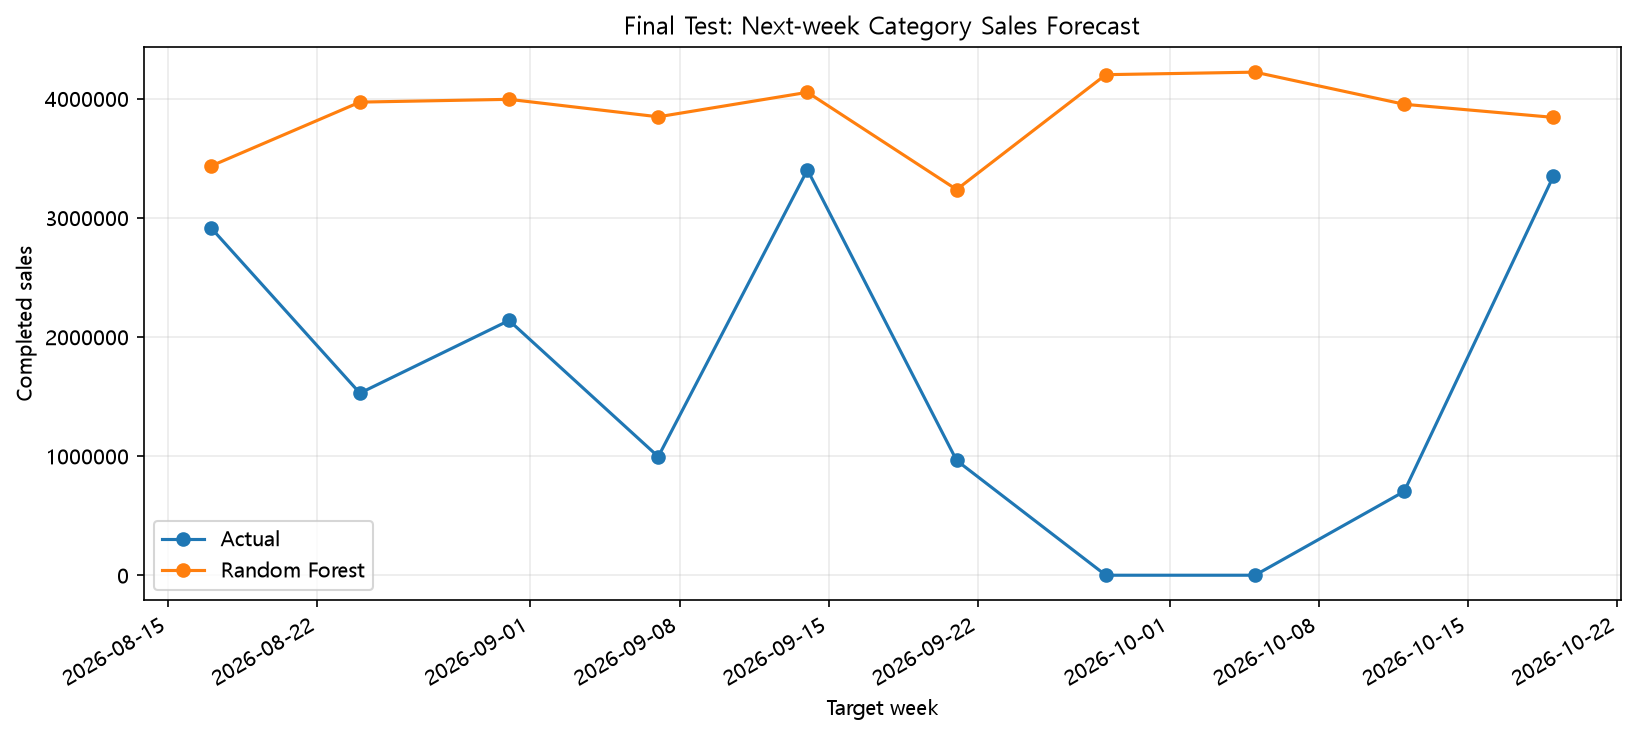

In [26]:
display(extension_result["cv_summary"].style.format({
    "CV_MAE_mean": "{:,.2f}", "CV_MAE_std": "{:,.2f}",
    "CV_RMSE_mean": "{:,.2f}", "CV_R2_mean": "{:.6f}",
}))
display(extension_result["comparison"].style.format({
    "test_MAE": "{:,.2f}", "test_RMSE": "{:,.2f}",
    "test_R2": "{:.6f}", "MAE_improvement_vs_baseline_pct": "{:.2f}%",
}))
display(extension_result["predictions"].head(10).style.format({
    "weekly_sales": "{:,.2f}", "predicted_weekly_sales": "{:,.2f}",
    "residual": "{:,.2f}", "absolute_error": "{:,.2f}",
}))
display(extension_result["validation"])
assert extension_result["validation"]["passed"].all()
from IPython.display import Image
display(Image(filename=str(extension_result["image_path"])))


### STEP 20. 시간 순서 학습·평가와 Baseline 비교

#### 시간 분할과 Pipeline

모델링 가능한 47개 Target 주 중 앞 37주(2025-12-01~2026-08-10, 259행)를 Train, 뒤 10주(2026-08-17~2026-10-19, 70행)를 Final Test로 고정했다. Train 최대 주가 Final Test 최소 주보다 이르고, Target 주 overlap은 0개다. 같은 주의 7개 카테고리는 항상 같은 fold에 들어가도록 Train의 고유 주에 `TimeSeriesSplit(n_splits=5)`를 적용했다. 수치형 중앙값 대치·표준화와 카테고리 One-Hot Encoding은 각 fold의 Pipeline 안에서만 fit했다.

Baseline은 직전 주의 같은 카테고리 완료 매출이다. 바로 계산할 수 있고, 모델이라면 최소한 "지난주 매출 그대로" 예측보다는 나아야 한다고 봤다. 후보는 Linear Regression과 Random Forest였다. Train CV 평균 MAE는 Random Forest 441,113.42원, Baseline 539,914.29원, Linear Regression 592,918.20원이었다. 따라서 Final Test를 보기 전에 후보 중 Random Forest를 동결했다. CV의 Random Forest RMSE는 565,341.63원, 평균 R²는 -0.552642로, MAE 순위는 가장 좋지만 설명력은 이미 약하다는 경고가 있었다.

#### Final Test 결과

| 모델 | 역할 | MAE | RMSE | R² | Baseline 대비 MAE |
| --- | --- | ---: | ---: | ---: | ---: |
| 직전 주 매출 | baseline | 330,800.00원 | 570,377.27원 | -1.170712 | 0.00% |
| Random Forest | selected_by_train_cv | 461,606.79원 | 505,910.60원 | -0.707754 | -39.54% |

Random Forest는 RMSE는 Baseline보다 약 6.4만원 낮았지만 MAE는 약 13.1만원 높았다. RMSE와 MAE의 방향이 반대라는 점은 일부 매우 큰 오류는 완화했지만 일반적인 카테고리·주 예측은 더 나빠졌음을 시사한다. 음수 R²는 두 방법 모두 Final Test의 평균 예측보다 변동을 잘 설명하지 못했다는 뜻이다. 선택 모델을 Final Test 결과에 맞춰 교체하지 않았으며, 이 실패도 그대로 Evidence로 남겼다.

가장 큰 Random Forest 오류는 2026-09-14 `Category 06`에서 실제 1,843,000원, 예측 740,218.62원, 잔차 +1,102,781.38원이었다. 두 번째는 2026-08-17 `Category 02`에서 실제 1,528,000원, 예측 598,892.01원, 잔차 +929,107.99원이었다. 반대로 2026-08-24 `Category 03`은 실제 0원인데 758,810.56원을 예측했다. 관찰된 패턴은 급증 주의 과소예측과 무판매 주의 과대예측이다. 짧은 lag·rolling Feature만으로는 드문 급증과 무판매 전환을 구분하기 어려웠을 가능성이 있지만, 현재 데이터에는 프로모션·재고 정보가 없어 원인으로 확정할 수는 없다.

따라서 현재 결과는 운영 사용 기준을 충족하지 못한다. 성능을 개선하려면 가격·할인·프로모션·재고/품절·유입량·휴일/이벤트와 2년 이상의 반복 계절 데이터를 예측 시점 기준으로 추가해 다시 검증할 필요가 있다.


### STEP 21. 확장 과제 결론

#### 1. 새롭게 정의한 예측 문제
현재 주 종료 시점에 7개 상품 카테고리 각각의 다음 주 `completed` 매출을 예측한다.

#### 2. 이 문제가 필요한 이유
이미 품목·수량·가격이 확정된 주문금액은 계산하면 되지만, 다음 주 수요는 아직 확정되지 않아 재고·발주·판매계획을 위해 사전 추정할 실익이 있다.

#### 3. Prediction Contract
단위는 `category×week`, Target은 다음 월~일 완료 매출, 예측 시점은 직전 일요일 종료, Horizon은 1주다. 결과는 검토 우선순위에만 사용하고 자동 발주에는 사용하지 않는다.

#### 4. Target과 Feature 설계
Target은 해당 주 `quantity×unit_price` 합계이며 무판매 주는 0원이다. Feature는 카테고리, 알려진 달력, 1·2주 전 매출, 직전 4주 평균 매출, 과거 주문수·수량 lag/rolling이다.

#### 5. Leakage Audit 결과
사용 Feature의 미래정보는 0개였다. rolling은 먼저 1주 shift했고, target 주 매출·수량·주문수와 원시 ID는 제외했다. `category×week` 중복도 0개다.

#### 6. 시간 분할 및 검증
Train은 37주·259행, Final Test는 이후 10주·70행이다. overlap 없이 주 단위로 묶었고, Train 내부 5-fold TimeSeriesSplit만으로 후보를 비교했다.

#### 7. Baseline과 모델 결과
직전 주 매출 Baseline의 Final Test MAE는 330,800.00원이었다. Train CV로 동결한 Random Forest의 MAE는 461,606.79원으로 약 13.1만원(39.54%) 더 나빴다. 모델 교체나 재선택은 하지 않았다.

#### 8. MAE / RMSE / R² 해석
Random Forest RMSE 505,910.60원은 Baseline 570,377.27원보다 낮아 극단 오차 일부는 줄였다. 하지만 MAE 악화와 R² -0.707754는 일반적 정확도와 설명력이 부족함을 보여 준다. Baseline R²도 -1.170712였다.

#### 9. 실제값과 예측값 비교의 주요 패턴
급격한 매출 증가를 과소예측하고, 실제 0원인 주를 큰 양수로 예측하는 사례가 함께 나타났다. 최대 절대오차는 1,102,781.38원이었다. 0원 비율 33.13%와 짧은 관측 기간이 이 불안정에 영향을 주었을 가능성이 있지만, 현재 결과만으로 원인을 확정할 수는 없다.

#### 10. 운영 사용 가능성
- [ ] 현재 수준에서 참고용 사용 가능
- [ ] 추가 검증 후 사용 가능
- [x] 현재 데이터로는 사용 보류

Train CV로 동결한 Random Forest는 Final Test에서 직전 주 매출 Baseline보다 MAE가 39.54% 나빴고 R²도 -0.707754로 음수였다. 기본 실습에서 Baseline보다 MAE가 6.66% 나빠 "사용 보류"로 판단한 것과 같은 기준을 적용하면 확장 과제도 현재 데이터로는 사용 보류가 일관된 판단이다. 문제 정의와 시간 분할·Pipeline 절차는 재사용할 수 있으므로, 더 긴 기간과 예측 시점에 확정된 추가 Feature를 확보한 뒤 새로운 미래 Final Test에서 Baseline보다 MAE가 낮아지는지 확인하고 사용 가능성을 다시 판단한다.

#### 11. 현재 데이터의 한계
완전한 기간은 51주뿐이고 모델링 시간점은 47주라 연간 계절성을 반복 관측하지 못했다. 표본 329행도 실제로는 47개 주가 카테고리별로 반복된 데이터다. Target 0원이 109행이며, 할인·프로모션·재고·품절·방문량·휴일 이벤트가 없다. 직전 주 `completed` 상태가 예측 시점에 확정되어 있다는 가정(STEP 18)도 데이터로 검증하지 못했다. 처음에는 Validation이 lag 결측 여부와 직접 작성한 감사표만 확인했기 때문에, 날짜 기준으로 lag·rolling 값을 직접 대조하는 검사(`lag_rolling_match_prior_weeks`)와 병합 결측 검사(`merge_keys_no_missing`)를 추가했다. 다만 이 검사들은 계산이 맞는지를 확인할 뿐, completed 상태가 예측 시점에 이미 확정되어 있었는지는 확인하지 못한다.

#### 12. 추가 데이터와 개선 방향
우선 2~3년 이상의 주간 이력을 확보한다. 다음으로 예측 시점에 확정된 가격/할인/프로모션 계획, 재고와 품절, 유입량, 휴일·행사 정보를 붙인다. 그다음 0원인 주가 많은 문제를 따로 다루는 방법, 더 긴 기간의 lag, 기간을 옮겨 가며 반복 평가하는 방법을 비교해 보고 싶다. 동일한 Final Test는 반복 튜닝에 재사용하지 않고 새 기간을 확보한다.


### STEP 22. LLM 활용 기록

LLM은 문제 정의, Target·Feature 후보, 누수 점검표, pandas 집계와 회귀 Pipeline 초안, 오류 원인 점검, 결과 해석 구조를 만드는 데 사용했다.

#### 주요 Prompt 요약

- 해결하려던 문제: 앞의 1~11번 답안은 그대로 두고, STEP 16~23의 미래 예측 과제를 실제 데이터로 실행해 Evidence와 답안을 완성하는 것.
- LLM에 준 자료: 작업 중인 노트북(`실습파일_완성.ipynb`), 작업 기준 문서, 질문별 작성가이드, 확장 과제 질문. `.venv`에서 실행하고, 원래 질문 문구는 유지하고, 실제 실행 결과만 쓰고, Final Test를 모델 선택에 쓰지 말라고 함께 요청했다.
- 요청한 작업: 후보 Target별로 표본이 충분한지 비교하고, Prediction Contract·Feature audit·시간 분할·Baseline·후보 모델·검증·시각화·결론을 하나의 노트북으로 이어 달라고 했다.
- 하지 말라고 한 것: 답안 예시 베끼기, 근거 없는 수치, 미래 정보가 들어간 Feature, Final Test를 보고 모델 고르기, 기존 1~11번 답안 수정, 패키지 설치.

#### LLM 제안과 수정

LLM은 월별 카테고리 매출, 주별 카테고리 매출, 고객 향후 구매금액을 후보로 제안했다. 실제 탐색에서 월은 13개뿐이어서 제외했고, 고객 문제는 반복 구매와 후속 관측기간이 부족할 위험이 커 제외했다. 주별 카테고리는 완전한 51주를 확보해 채택했다. 처음 데이터 로더에는 products가 없어 `products_clean.csv`를 별도로 결합했고, 문자열 날짜의 `.normalize()` 오류는 명시적 `pd.to_datetime` 변환으로 수정했다.

Feature 제안은 그대로 채택하지 않고 실제 예측 시점을 기준으로 검사했다. target 주 매출·수량·주문수와 ID는 제외하고, lag와 rolling은 `shift(1)` 이후 계산했다. 행 단위 분할은 같은 주가 양쪽에 섞이므로 고유 주를 먼저 나눈 뒤 모든 카테고리를 같은 fold에 배치했다.

#### 제안별 채택 / 수정 / 보류

| LLM 제안 | 실제 실행·확인 결과 | 결정 |
| --- | --- | --- |
| 월별 카테고리 매출 Target | 관측 월 13개로 시간 분할·CV가 불안정 | 보류 |
| 고객별 향후 30일 구매금액 Target | 반복 구매와 후속 관측기간 부족 위험 | 보류 |
| 주별 카테고리 매출 Target | 완전한 51주×7개 카테고리, 모델링 329행 확보 | 채택 |
| 기존 데이터 로더로 카테고리 사용 | 로더에 products가 없음 | 수정(`products_clean.csv` 별도 결합) |
| 행 단위 시간 분할 | 같은 주가 Train/Test에 섞일 위험 | 수정(고유 주 단위 분할) |
| lag/rolling Feature | `shift(1)` 후 계산, 사용 Feature 미래정보 0개 확인 | 수정 후 채택 |
| Train CV 최저 MAE 모델(Random Forest) 동결 | Final Test에서 Baseline보다 MAE 39.54% 악화 | 동결 유지, 사용 판단은 내가 보류로 결정 |

#### 실행·검증·나의 판단

코드는 `.venv`에서 실행했고, 키 중복 0개, 병합 결측 0개, 날짜 기준 lag·rolling 값 일치, 사용 Feature 미래정보 0개, Train/Test 주 overlap 0개, Pipeline 내부 fit, 고정 모델 역할, 공개 결과의 원시 ID 부재를 검증했다. LLM은 Random Forest가 Train CV 후보 중 가장 낮은 MAE라는 사실을 정리했지만, 최종 사용 판단은 실제 Final Test에서 Baseline보다 MAE가 39.54% 악화한 Evidence를 근거로 내가 직접 “운영 사용 보류, 추가 데이터 후 재검증”으로 내렸다. 낮은 성능을 감추거나 Final Test를 보고 다른 후보로 교체하지 않았다.


In [27]:
# 같은 환경에서 확장 분석을 한 번 더 실행해 결과가 똑같이 나오는지 확인한다.
extension_repeat = run_extension_analysis(save_artifacts=False)
metric_columns = ["test_MAE", "test_RMSE", "test_R2", "MAE_improvement_vs_baseline_pct"]
metric_max_diff = float(np.abs(
    extension_result["comparison"][metric_columns].to_numpy()
    - extension_repeat["comparison"][metric_columns].to_numpy()
).max())
prediction_max_diff = float(np.abs(
    extension_result["predictions"]["predicted_weekly_sales"].to_numpy()
    - extension_repeat["predictions"]["predicted_weekly_sales"].to_numpy()
).max())
evidence_exists = {path.name: path.exists() for path in extension_result["evidence_paths"]}
evidence_exists[extension_result["image_path"].name] = extension_result["image_path"].exists()

print("선택 모델 재현:", extension_result["selected_model"] == extension_repeat["selected_model"])
print("평가지표 최대 차이:", metric_max_diff)
print("예측값 최대 차이:", prediction_max_diff)
print("필수 Evidence 존재:", all(evidence_exists.values()))
display(pd.Series(evidence_exists, name="exists").to_frame())
assert extension_result["validation"]["passed"].all()
assert metric_max_diff == 0.0
assert prediction_max_diff == 0.0
assert all(evidence_exists.values())


선택 모델 재현: True
평가지표 최대 차이: 0.0
예측값 최대 차이: 0.0
필수 Evidence 존재: True


,exists
ch09_extension_model_data_internal.csv,True
ch09_extension_feature_audit.csv,True
ch09_extension_split_summary.csv,True
ch09_extension_cv_detail.csv,True
ch09_extension_cv_summary.csv,True
ch09_extension_model_comparison.csv,True
ch09_extension_predictions_internal.csv,True
ch09_extension_validation.csv,True
final_prediction_result.png,True
